# 🏦 Unified Risk Analysis — Credit Risk + Fraud Decision Engine

**Project:** AI Loan Underwriting Platform (capstone) — decision-engine module  
**Inputs:** Give Me Some Credit (credit risk, `cs-training.csv`) + Credit Card Fraud Detection (ULB, fraud)  
**Output:** One **APPROVE / REVIEW / DECLINE** decision per applicant, built from a calibrated **Probability of Default (PD)** and a calibrated **fraud probability**  
**Author:** Narendra Kalam

---

## 🏦 Business Problem

A lender faces two *different* risks on every application. **Credit risk:** will this borrower repay? **Fraud risk:** is this application / identity / transaction genuine? A credit model alone approves fraudsters with good-looking credit profiles; a fraud model alone approves genuine but risky borrowers. The platform needs one decision rule that combines both, is explainable, and is justified in **money**, not only in AUC.

**Key challenges:**
- The two scores live on different scales and different base rates (≈ 6.7% default vs ≈ 0.17% fraud) — they must be **calibrated** before they can be combined
- Manual review is expensive — the rule must control **review workload**, not just error rates
- Thresholds must be chosen on economics (loss, margin, review cost), on data **separate** from the data used to report results
- The decision must be stress-tested against the assumption that credit risk and fraud risk are unrelated
- Approval rates must be checked across customer segments (age) before a rule goes live

> ⚠️ **Important data limitation:** the two Kaggle datasets describe *different people* and share **no applicant key**. A real joint dataset does not exist here. This notebook therefore **simulates** an application portfolio by pairing credit applicants with fraud-scored records (Steps 8–13). The simulation validates the **decision logic, cost model and threshold method** — not the true joint distribution. Step 12 stress-tests the independence assumption.  
> 📝 Every number in the Observation blocks is read from the executed outputs and plots of this notebook (seed 42, simulated portfolio). Re-run and re-check them if the data, the seed or the cost assumptions change.  
> 💰 All cost parameters in Step 1 are **illustrative assumptions** — replace them with your portfolio's real loan size, margin, LGD and review cost.

---

## 📌 Notebook Workflow

| Step | Topic |
|------|-------|
| 1 | Import libraries, configuration and cost assumptions |
| 2 | Data loading, EDA rules and stratified splits |
| 3 | Credit PD model — train, calibrate, evaluate |
| 4 | Fraud scoring model — train, calibrate, evaluate |
| 5 | Calibration check and score distributions |
| 6 | Single-model operating curves (credit strategy curve, fraud workload) |
| 7 | Decision matrix design (PD band × fraud band) |
| 8 | Simulated application portfolio |
| 9 | Economic model and policy evaluation |
| 10 | Threshold optimisation on the tuning portfolio |
| 11 | Policy comparison on the unseen evaluation portfolio |
| 12 | Dependence stress test (credit–fraud correlation) |
| 13 | Segment and fairness check by age band |
| 14 | Model drivers and reason-code preview |
| 15 | Key insights summary and decision-engine export |

---

---
## Step 1 — Import Libraries, Configuration and Cost Assumptions
---
**Why:** One configuration cell holds the seed, file paths, feature lists and **every economic assumption**. Keeping the cost parameters in one place makes the threshold analysis transparent and lets the business re-run the whole notebook with real numbers.  

**Business insight:** A decision rule is only as good as the economics behind it. Loan size, net margin, loss-given-default, fraud loss and review cost decide where thresholds belong — a rule tuned for a 5% margin portfolio would be wrong for a 15% margin one.

In [1]:
import json
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mticker
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             roc_curve, precision_recall_curve)

# ── Plot style ────────────────────────────────────────────────
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"figure.dpi": 120, "figure.figsize": (12, 5), "axes.titlesize": 13,
                     "axes.titleweight": "bold", "axes.labelsize": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
BAD_COLOR, GOOD_COLOR, ACCENT_COLOR, WARN_COLOR = "#E74C3C", "#2ECC71", "#3498DB", "#F39C12"
DEC_COLORS = {0: GOOD_COLOR, 1: WARN_COLOR, 2: BAD_COLOR}
DEC_NAMES  = {0: "APPROVE", 1: "REVIEW", 2: "DECLINE"}

# ── Reproducibility ───────────────────────────────────────────
SEED = 42

# ── Data locations (first existing path wins) ─────────────────
CREDIT_PATHS = [Path(r"D:\Data_Science_Capstone_Datasets\ai-loan-underwriting-platform\GiveMeSomeCredit\cs-training.csv"), Path("data/raw/cs-training.csv"), Path("cs-training.csv")]
FRAUD_PATHS  = [Path(r"D:\Data Science Datasets\Credit Card Fraud Detection.csv"), Path("data/raw/creditcard.csv"), Path("creditcard.csv")]
REPORT_DIR = Path("reports"); REPORT_DIR.mkdir(exist_ok=True)

# ── Economic assumptions (ILLUSTRATIVE — replace with real portfolio values) ──
LOAN_AMOUNT          = 10_000   # average loan size
MARGIN_RATE          = 0.08     # net revenue on a loan that repays
LGD                  = 0.60     # loss given default (share of loan lost on a defaulted loan)
FRAUD_LOSS_RATE      = 1.00     # share of loan lost when a fraudulent application is approved
REVIEW_COST          = 25       # analyst cost per manually reviewed case
REVIEW_FRAUD_CATCH   = 0.85     # share of fraud cases an analyst correctly declines
REVIEW_CREDIT_CATCH  = 0.50     # share of defaulting borrowers an analyst correctly declines
REVIEW_FALSE_DECLINE = 0.10     # share of good cases an analyst wrongly declines
APP_FRAUD_RATE       = 0.01     # ASSUMED fraud prevalence among loan applications (transactions: ~0.17%)

print("✅ Libraries imported")
print(f"   Margin per good loan : ${LOAN_AMOUNT * MARGIN_RATE:,.0f}")
print(f"   Loss per default     : ${LOAN_AMOUNT * LGD:,.0f}")
print(f"   Loss per fraud       : ${LOAN_AMOUNT * FRAUD_LOSS_RATE:,.0f}")
print(f"   Review cost          : ${REVIEW_COST}")

✅ Libraries imported
   Margin per good loan : $800
   Loss per default     : $6,000
   Loss per fraud       : $10,000
   Review cost          : $25


📌 **Observation:**

- The assumed economics are asymmetric: one approved fraud case (−$10,000) erases the margin of **12.5 good loans** ($800 each), one default (−$6,000) erases **7.5**, while a manual review costs only **$25** — 1/32 of one good loan's margin.
- A review is therefore cheap relative to a wrong approval, but reviewing every applicant (Step 9) is not free either: it costs $25 per applicant, about 3% of the margin on a good loan.

💡 **Pipeline decision:** All cost parameters are stored in `config/decision_economics.yaml` and exported with the thresholds in Step 15, so every threshold is traceable to the economics that produced it. Thresholds are re-tuned whenever margin, LGD, fraud prevalence or review capacity change.

---
## Step 2 — Data Loading, EDA Rules and Stratified Splits
---
**Why:** Both datasets are loaded, de-duplicated and cleaned with the rules decided in the two EDA notebooks, so that the models here are built on exactly the data contract the production pipeline will enforce. Each dataset is split **three ways** — model-fit, calibration and hold-out — because calibration and final reporting must never reuse the data a model was fitted on.  

**Business insight:** Credit-risk rules (96/98 sentinel codes, `age < 18`, DTI repair, winsorisation) and fraud rules (de-duplication, `log1p(Amount)`, cyclic hour) are not optional preprocessing — they are the documented data-quality controls that model-risk reviewers will ask about.

In [2]:
# ═════════ CREDIT RISK (Give Me Some Credit) — rules from 02_credit_risk_eda ═════════
CREDIT_RENAME = {
    "SeriousDlqin2yrs": "default", "RevolvingUtilizationOfUnsecuredLines": "revolving_util", "age": "age",
    "NumberOfTime30-59DaysPastDueNotWorse": "past_due_30_59", "DebtRatio": "debt_ratio",
    "MonthlyIncome": "monthly_income", "NumberOfOpenCreditLinesAndLoans": "open_credit_lines",
    "NumberOfTimes90DaysLate": "late_90", "NumberRealEstateLoansOrLines": "real_estate_loans",
    "NumberOfTime60-89DaysPastDueNotWorse": "past_due_60_89", "NumberOfDependents": "dependents"}
DELINQ = ["past_due_30_59", "past_due_60_89", "late_90"]
CREDIT_FEATURES = ["revolving_util", "age", "debt_ratio", "log_income", "open_credit_lines", "real_estate_loans",
                   "dependents", "total_delinq", "severity_score", "monthly_debt_payment",
                   "over_limit_flag", "delinq_sentinel_flag", "income_missing", "dependents_missing"]
# business logic: more utilisation / more delinquency can never lower risk (monotonic +1)
CREDIT_MONOTONIC = [1 if f in ("revolving_util", "total_delinq", "severity_score") else 0 for f in CREDIT_FEATURES]

credit_path = next((p for p in CREDIT_PATHS if p.exists()), None)
assert credit_path is not None, "cs-training.csv not found — update CREDIT_PATHS"
credit = pd.read_csv(credit_path, index_col=0).rename(columns=CREDIT_RENAME).drop_duplicates().reset_index(drop=True)

c_train_full, c_hold = train_test_split(credit, test_size=0.20, stratify=credit["default"], random_state=SEED)
c_fit, c_cal = train_test_split(c_train_full, test_size=0.25, stratify=c_train_full["default"], random_state=SEED)

# caps / medians learned on the model-fit split ONLY
CAPS = {"revolving_util": float(c_fit["revolving_util"].quantile(0.99)),
        "debt_ratio": float(c_fit.loc[c_fit["monthly_income"].notna(), "debt_ratio"].quantile(0.99)),
        "monthly_income": float(c_fit["monthly_income"].quantile(0.995))}
AGE_MEDIAN = float(c_fit.loc[c_fit["age"] >= 18, "age"].median())

def credit_features(d):
    d = d.copy()
    d["delinq_sentinel_flag"] = (d[DELINQ] >= 96).any(axis=1).astype(int)
    d[DELINQ] = d[DELINQ].where(d[DELINQ] < 96).fillna(0)
    d["age"] = d["age"].where(d["age"] >= 18).fillna(AGE_MEDIAN)
    d["income_missing"] = d["monthly_income"].isna().astype(int)
    d["dependents_missing"] = d["dependents"].isna().astype(int)
    d.loc[d["income_missing"] == 1, "debt_ratio"] = np.nan
    d["over_limit_flag"] = (d["revolving_util"] > 1).astype(int)
    d["revolving_util"] = d["revolving_util"].clip(upper=CAPS["revolving_util"])
    d["total_delinq"] = d[DELINQ].sum(axis=1)
    d["severity_score"] = d["past_due_30_59"] + 2 * d["past_due_60_89"] + 3 * d["late_90"]
    d["monthly_debt_payment"] = d["debt_ratio"] * d["monthly_income"]
    d["log_income"] = np.log1p(d["monthly_income"].clip(upper=CAPS["monthly_income"]))
    d["debt_ratio"] = d["debt_ratio"].clip(upper=CAPS["debt_ratio"])
    d["dependents"] = d["dependents"].fillna(0)
    return d[CREDIT_FEATURES]

Xc_fit = credit_features(c_fit)
CREDIT_MEDIANS = Xc_fit.median()
Xc_fit = Xc_fit.fillna(CREDIT_MEDIANS)
Xc_cal, Xc_hold = (credit_features(d).fillna(CREDIT_MEDIANS) for d in (c_cal, c_hold))
yc_fit, yc_cal, yc_hold = c_fit["default"], c_cal["default"], c_hold["default"]

# ═════════ FRAUD (ULB) — rules from 01_fraud_eda ═════════
V_COLS = [f"V{i}" for i in range(1, 29)]
FRAUD_FEATURES = V_COLS + ["log_amount", "hour_sin", "hour_cos"]      # raw `day` and graph score deliberately excluded

fraud_path = next((p for p in FRAUD_PATHS if p.exists()), None)
assert fraud_path is not None, "Credit Card Fraud Detection.csv not found — update FRAUD_PATHS"
fraud = pd.read_csv(fraud_path).drop_duplicates().reset_index(drop=True)

def fraud_features(d):
    X = d[V_COLS].copy()
    X["log_amount"] = np.log1p(d["Amount"])
    hour = (d["Time"] // 3600) % 24
    X["hour_sin"], X["hour_cos"] = np.sin(2 * np.pi * hour / 24), np.cos(2 * np.pi * hour / 24)
    return X[FRAUD_FEATURES]

f_train_full, f_hold = train_test_split(fraud, test_size=0.20, stratify=fraud["Class"], random_state=SEED)
f_fit, f_cal = train_test_split(f_train_full, test_size=0.25, stratify=f_train_full["Class"], random_state=SEED)
Xf_fit, Xf_cal, Xf_hold = (fraud_features(d) for d in (f_fit, f_cal, f_hold))
yf_fit, yf_cal, yf_hold = f_fit["Class"], f_cal["Class"], f_hold["Class"]
FRAUD_PRIOR = float(fraud["Class"].mean())

split_tbl = pd.DataFrame({
    "credit rows":  [len(c_fit), len(c_cal), len(c_hold)], "credit default %": [yc_fit.mean()*100, yc_cal.mean()*100, yc_hold.mean()*100],
    "fraud rows":   [len(f_fit), len(f_cal), len(f_hold)], "fraud %": [yf_fit.mean()*100, yf_cal.mean()*100, yf_hold.mean()*100],
}, index=["model-fit", "calibration", "hold-out"])
display(split_tbl.round(3))
print(f"Fraud frauds per split → fit {int(yf_fit.sum())} | calibration {int(yf_cal.sum())} | hold-out {int(yf_hold.sum())}")

,credit rows,credit default %,fraud rows,fraud %
model-fit,89634,6.699,170235,0.167
calibration,29878,6.701,56745,0.166
hold-out,29879,6.700,56746,0.167


Fraud frauds per split → fit 284 | calibration 94 | hold-out 95


📌 **Observation:**

- Credit split: **89,634 fit / 29,878 calibration / 29,879 hold-out** rows, with default rates of 6.699%, 6.701% and 6.700% — the stratification is exact. Fraud split: **170,235 / 56,745 / 56,746** rows at 0.167%, 0.166% and 0.167%.
- The fraud side is the fragile one: only **284 frauds in the fit split, 94 in calibration and 95 in the hold-out**. Every fraud metric below is based on 95 positive cases, so one missed fraud moves recall by about 1.05 percentage points.

💡 **Pipeline decision:** Caps, medians and the age median are learned on the **model-fit split only** and serialised with the model (train/serve parity). `day` and `graph_risk_score` are excluded from the fraud features, as concluded in `01_fraud_eda` (two-valued `day` is not a usable predictor; the graph score is constant). In production the fraud calibration set must be enlarged with a time-based hold-out from a longer history — 94 positives are too few for a stable calibrator.

---
## Step 3 — Credit PD Model: Train, Calibrate, Evaluate
---
**Why:** A gradient-boosted tree model with **monotonic constraints** on utilisation and delinquency features captures non-linear risk while obeying business logic (more late payments can never lower risk). Raw boosted scores are not probabilities, so an **isotonic calibration** step, fitted on a separate calibration set, turns them into a usable Probability of Default.  

**Business insight:** Underwriting uses PD for approval cut-offs, pricing and loss provisioning. A model that ranks well but outputs inflated probabilities breaks every one of those uses — which is why discrimination (AUC, KS) *and* calibration (Brier) are both reported.

,ROC-AUC,PR-AUC,KS,Brier,mean score,actual rate
model,,,,,,
raw (class-weighted),0.8651,0.4005,0.5856,0.1467,0.3236,0.067
calibrated PD,0.8648,0.3873,0.5852,0.0490,0.0685,0.067


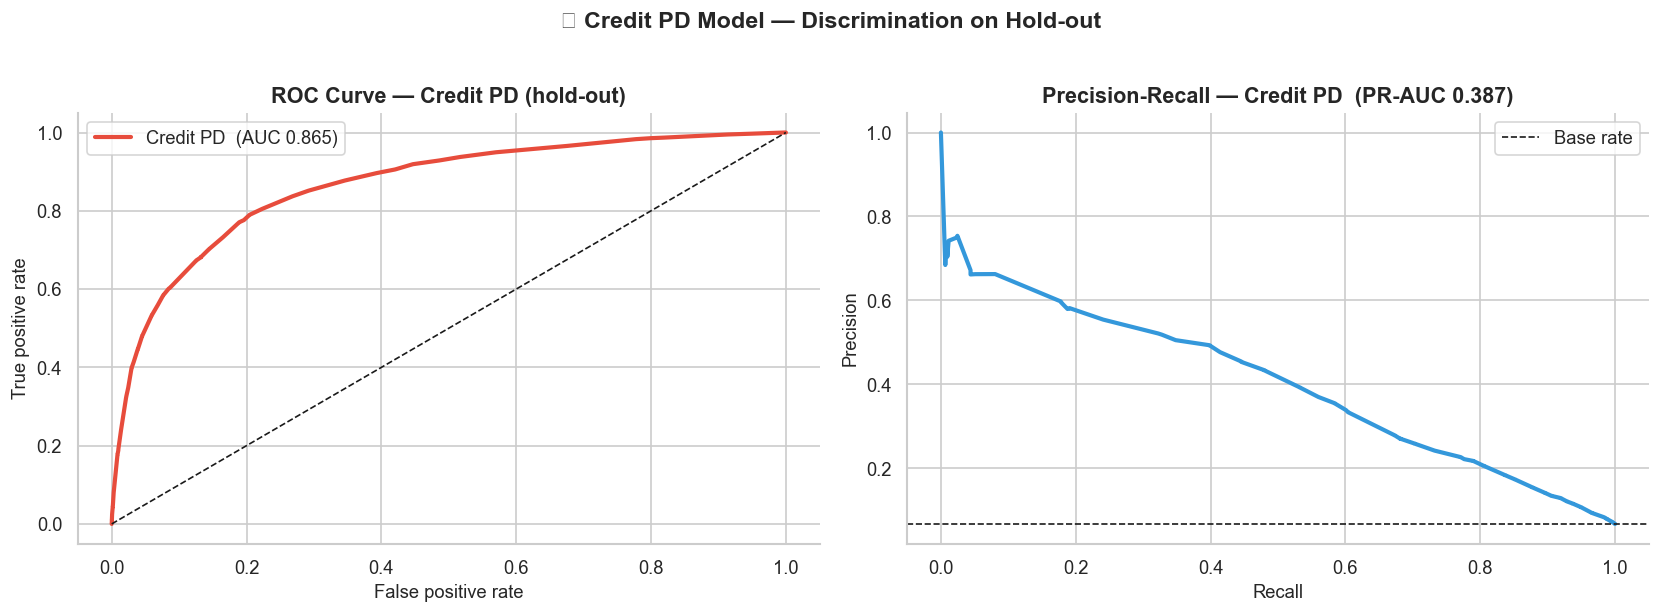

In [3]:
def ks_stat(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    return float(np.max(tpr - fpr))

def report(name, y, p):
    return {"model": name, "ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
            "KS": ks_stat(y, p), "Brier": brier_score_loss(y, p), "mean score": p.mean(), "actual rate": y.mean()}

credit_gbm = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=100,
                                            l2_regularization=1.0, monotonic_cst=CREDIT_MONOTONIC,
                                            early_stopping=True, validation_fraction=0.1, random_state=SEED)
credit_gbm.fit(Xc_fit, yc_fit, sample_weight=compute_sample_weight("balanced", yc_fit))

raw_cal, raw_hold = credit_gbm.predict_proba(Xc_cal)[:, 1], credit_gbm.predict_proba(Xc_hold)[:, 1]
credit_iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(raw_cal, yc_cal)
pd_hold = credit_iso.predict(raw_hold)

credit_res = pd.DataFrame([report("raw (class-weighted)", yc_hold, raw_hold), report("calibrated PD", yc_hold, pd_hold)]).set_index("model")
display(credit_res.round(4))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
fpr, tpr, _ = roc_curve(yc_hold, pd_hold)
ax[0].plot(fpr, tpr, color=BAD_COLOR, lw=2.5, label=f"Credit PD  (AUC {roc_auc_score(yc_hold, pd_hold):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set_title("ROC Curve — Credit PD (hold-out)")
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate"); ax[0].legend()
pr, rc, _ = precision_recall_curve(yc_hold, pd_hold)
ax[1].plot(rc, pr, color=ACCENT_COLOR, lw=2.5); ax[1].axhline(yc_hold.mean(), color="k", ls="--", lw=1, label="Base rate")
ax[1].set_title(f"Precision-Recall — Credit PD  (PR-AUC {average_precision_score(yc_hold, pd_hold):.3f})")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].legend()
plt.suptitle("📈 Credit PD Model — Discrimination on Hold-out", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

📌 **Observation:**

- Hold-out discrimination of the credit model: **ROC-AUC 0.865, KS 0.585** (calibrated PD: 0.8648 / 0.5852). In the ROC plot the curve reaches a true-positive rate of about **0.79 at a 20% false-positive rate** and about 0.65 at 10%.
- Precision-Recall plot (PR-AUC **0.387**; base rate 0.067): precision is about 0.65 for the top-scored 5–10% of defaulters, ~0.5 at 40% recall, ~0.33 at 60% recall and ~0.2 at 80% recall — still 3× the base rate even at high recall.
- Calibration changes the scale, not the ordering: the raw class-weighted score has a **mean of 0.324 against an actual rate of 0.067** and a Brier score of **0.1467**; after isotonic calibration the mean is **0.0685** and the Brier score falls to **0.0490**, while ROC-AUC (0.8651 → 0.8648) and KS are unchanged. PR-AUC drops slightly (0.4005 → 0.3873) because isotonic regression creates tied score plateaus.

💡 **Pipeline decision:** The credit champion is **gradient boosting + monotonic constraints + isotonic calibration**, with the WoE-logistic scorecard as the explainable challenger (per `02_credit_risk_eda`). Because isotonic output is a step function (it cannot exceed ≈ 0.39 here, see Step 5), production should test a smoother calibrator (Platt or spline) once more calibration data is available. Discrimination metrics come from the untouched hold-out only.

---
## Step 4 — Fraud Scoring Model: Train, Calibrate, Evaluate
---
**Why:** The fraud model uses the same gradient-boosting family on `V1–V28`, `log_amount` and cyclic hour. With only a few dozen positives in the calibration set, a flexible isotonic calibrator would overfit, so a **Platt (sigmoid) calibrator** — two parameters — is used instead. **PR-AUC** is the primary metric because ROC-AUC is optimistic at a 600 : 1 imbalance.  

**Business insight:** The fraud score will be compared directly with the PD and used to trigger reviews. A fraud score of "0.30" must mean roughly "30% of such applications are fraudulent" — otherwise review queues are sized wrongly and thresholds are meaningless.

,ROC-AUC,PR-AUC,KS,Brier,mean score,actual rate
model,,,,,,
raw (weighted),0.94263,0.77958,0.84845,0.00057,0.00365,0.00167
calibrated (Platt),0.94263,0.77958,0.84845,0.00049,0.00152,0.00167


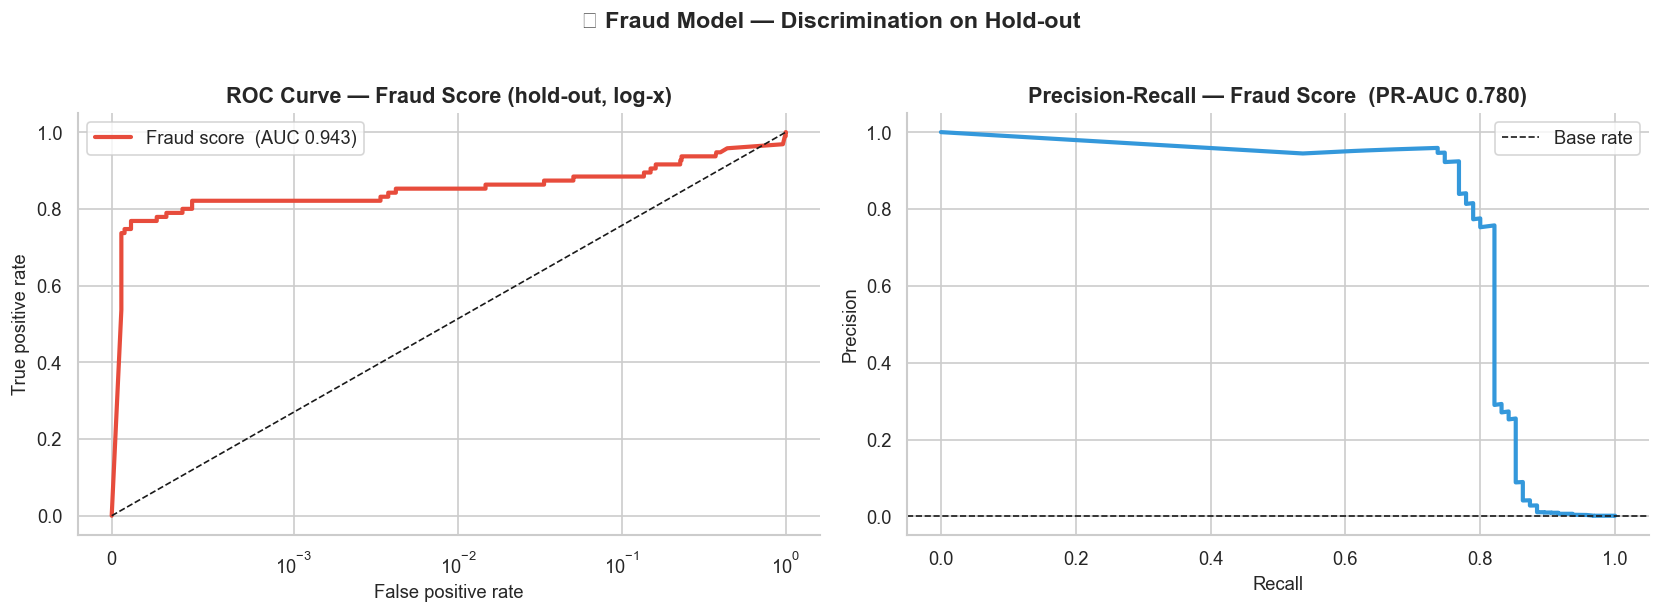

Hold-out frauds: 95  → PR-AUC differences of a few points are within noise at this sample size


In [4]:
def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)

fraud_gbm = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, max_leaf_nodes=31, min_samples_leaf=20,
                                           l2_regularization=1.0, early_stopping=True, validation_fraction=0.1, random_state=SEED)
w_f = np.where(yf_fit == 1, 30.0, 1.0)            # moderate positive weight; Platt recalibrates afterwards
fraud_gbm.fit(Xf_fit, yf_fit, sample_weight=w_f)

rawf_cal, rawf_hold = fraud_gbm.predict_proba(Xf_cal)[:, 1], fraud_gbm.predict_proba(Xf_hold)[:, 1]
fraud_platt = LogisticRegression(C=1e6, max_iter=1000).fit(logit(rawf_cal), yf_cal)
fs_hold = fraud_platt.predict_proba(logit(rawf_hold))[:, 1]

fraud_res = pd.DataFrame([report("raw (weighted)", yf_hold, rawf_hold), report("calibrated (Platt)", yf_hold, fs_hold)]).set_index("model")
display(fraud_res.round(5))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
fpr, tpr, _ = roc_curve(yf_hold, fs_hold)
ax[0].plot(fpr, tpr, color=BAD_COLOR, lw=2.5, label=f"Fraud score  (AUC {roc_auc_score(yf_hold, fs_hold):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set_xscale("symlog", linthresh=1e-3)
ax[0].set_title("ROC Curve — Fraud Score (hold-out, log-x)"); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate"); ax[0].legend()
pr, rc, _ = precision_recall_curve(yf_hold, fs_hold)
ax[1].plot(rc, pr, color=ACCENT_COLOR, lw=2.5); ax[1].axhline(yf_hold.mean(), color="k", ls="--", lw=1, label="Base rate")
ax[1].set_title(f"Precision-Recall — Fraud Score  (PR-AUC {average_precision_score(yf_hold, fs_hold):.3f})")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].legend()
plt.suptitle("🚨 Fraud Model — Discrimination on Hold-out", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()
print(f"Hold-out frauds: {int(yf_hold.sum())}  → PR-AUC differences of a few points are within noise at this sample size")

📌 **Observation:**

- Hold-out discrimination of the fraud model: **ROC-AUC 0.943, PR-AUC 0.780, KS 0.848** — identical before and after Platt scaling, since a monotonic recalibration cannot change the ranking. Calibration moves the mean score from **0.00365 to 0.00152** (actual rate 0.00167) and the Brier score from 0.00057 to 0.00049.
- ROC plot (log x-axis): the curve shoots up to a true-positive rate of **0.73–0.77 at a false-positive rate below 0.1%**, then goes almost flat at **≈ 0.82** across 0.1%–0.4% FPR and only creeps to 0.85–0.88 by 10% FPR. About one fraud in five is ranked among legitimate transactions; that long flat tail is what holds ROC-AUC at 0.943.
- Precision-Recall plot: precision stays at **0.95–1.0 up to ≈ 75% recall**, then falls off a cliff near **82% recall** (to ~0.25–0.3) and to almost zero beyond 88%.
- The calibrated mean (0.00152) is ~9% below the true rate — slightly under-predicting, with only 94 calibration positives.

💡 **Pipeline decision:** Fraud model = **gradient boosting + Platt calibration**, evaluated on **PR-AUC and alerts-per-fraud-caught**. The ~18% of frauds that the model cannot separate from legitimate traffic will not be fixed by tuning — they need additional signals (device, identity, behavioural). Model comparison in production must use repeated stratified CV or a longer time-based hold-out: a single split with 95 frauds cannot rank two close models.

---
## Step 5 — Calibration Check and Score Distributions
---
**Why:** A **reliability diagram** plots predicted probability against the observed event rate in each score bucket; points on the diagonal mean the score can be read as a probability. Score histograms by class show how cleanly each model separates good from bad, and where overlapping (ambiguous) cases live — the natural REVIEW region.  

**Business insight:** If the PD is mis-calibrated, expected-loss and pricing numbers are wrong; if the fraud score is mis-calibrated, review queues are mis-sized. Calibration is a risk-management requirement, not a cosmetic step.

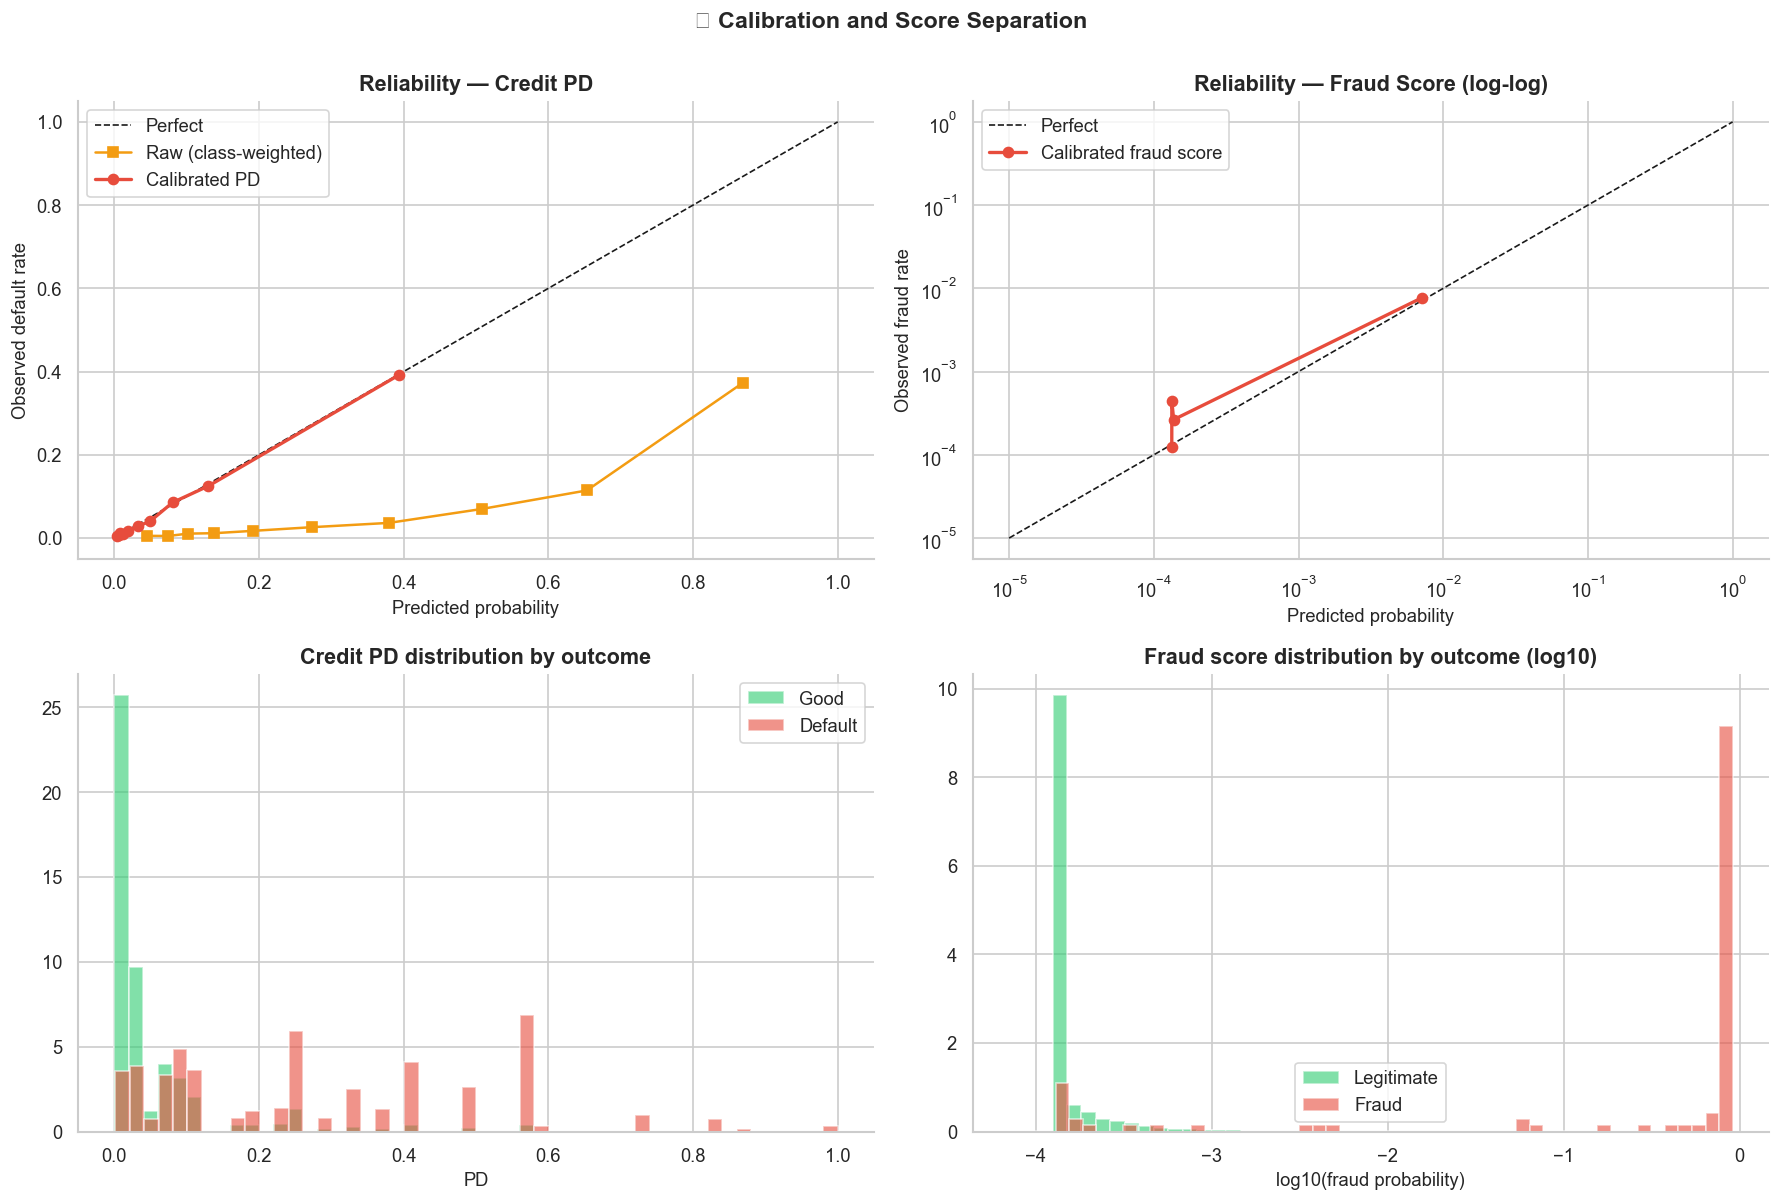

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# reliability — credit PD
frac, mean_p = calibration_curve(yc_hold, pd_hold, n_bins=10, strategy="quantile")
fr_raw, mp_raw = calibration_curve(yc_hold, np.clip(raw_hold, 0, 1), n_bins=10, strategy="quantile")
axes[0, 0].plot([0, 1], [0, 1], "k--", lw=1, label="Perfect")
axes[0, 0].plot(mp_raw, fr_raw, "s-", color=WARN_COLOR, label="Raw (class-weighted)")
axes[0, 0].plot(mean_p, frac, "o-", color=BAD_COLOR, lw=2, label="Calibrated PD")
axes[0, 0].set_title("Reliability — Credit PD"); axes[0, 0].set_xlabel("Predicted probability"); axes[0, 0].set_ylabel("Observed default rate"); axes[0, 0].legend()

# reliability — fraud (few positives → 5 quantile bins on a log scale)
frac_f, mean_f = calibration_curve(yf_hold, fs_hold, n_bins=5, strategy="quantile")
axes[0, 1].plot([1e-5, 1], [1e-5, 1], "k--", lw=1, label="Perfect")
axes[0, 1].plot(np.clip(mean_f, 1e-5, 1), np.clip(frac_f, 1e-5, 1), "o-", color=BAD_COLOR, lw=2, label="Calibrated fraud score")
axes[0, 1].set_xscale("log"); axes[0, 1].set_yscale("log")
axes[0, 1].set_title("Reliability — Fraud Score (log-log)"); axes[0, 1].set_xlabel("Predicted probability"); axes[0, 1].set_ylabel("Observed fraud rate"); axes[0, 1].legend()

# score distributions by class
for lbl, col, nm in [(0, GOOD_COLOR, "Good"), (1, BAD_COLOR, "Default")]:
    axes[1, 0].hist(pd_hold[yc_hold == lbl], bins=50, alpha=0.6, color=col, density=True, label=nm)
axes[1, 0].set_title("Credit PD distribution by outcome"); axes[1, 0].set_xlabel("PD"); axes[1, 0].legend()
for lbl, col, nm in [(0, GOOD_COLOR, "Legitimate"), (1, BAD_COLOR, "Fraud")]:
    axes[1, 1].hist(np.log10(np.clip(fs_hold[yf_hold == lbl], 1e-6, 1)), bins=50, alpha=0.6, color=col, density=True, label=nm)
axes[1, 1].set_title("Fraud score distribution by outcome (log10)"); axes[1, 1].set_xlabel("log10(fraud probability)"); axes[1, 1].legend()

plt.suptitle("🎯 Calibration and Score Separation", fontsize=14, fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()

📌 **Observation:**

- **Credit reliability:** the calibrated PD lies on the diagonal up to its maximum of about **0.39** (predicted 0.39 → observed 0.39); the raw class-weighted score lies far below it (raw 0.87 → observed ≈ 0.37; raw 0.4 → observed ≈ 0.04). The calibrated model cannot output a PD above ≈ 0.4 because of the isotonic plateaus.
- **Credit score distribution:** good borrowers form a huge spike at PD < 0.02 (density ≈ 25); defaulters are spread from 0 to 1 with isotonic steps at ≈ 0.25, 0.4 and 0.57. Good and bad overlap heavily between PD ≈ 0.03 and 0.15.
- **Fraud reliability:** only four points survive the quantile binning — three stacked at a predicted ≈ 1.3×10⁻⁴ (observed 1.2×10⁻⁴ to 4.4×10⁻⁴) and one at ≈ 7×10⁻³ (observed ≈ 7.5×10⁻³). They sit close to the diagonal but are based on very few positives, so no tighter statement is possible.
- **Fraud score distribution (log10):** legitimate transactions form a huge spike at **log10 ≈ −3.85** (the score floor, ≈ 1.4×10⁻⁴), and fraud forms an equally tall spike near **log10 ≈ −0.05 (score ≈ 0.9)** — strongly bimodal. A small block of fraud sits at the same floor as legitimate transactions: the missed frauds.

💡 **Pipeline decision:** Credit risk needs a **wide REVIEW / risk-based-pricing band**, because good and bad overlap broadly; fraud separates sharply, so its rule is "decline above a high threshold". The unified rule must also handle the floor: all transactions below ≈ 2×10⁻⁴ receive the same score. A **calibration monitor** (reliability and Brier by month, with bootstrap intervals for fraud) goes onto the Streamlit dashboard, and retraining is triggered when calibration drifts.

---
## Step 6 — Single-Model Operating Curves
---
**Why:** Before combining anything, each model's own trade-off must be understood. For credit risk the standard tool is the **strategy curve** — approval rate against the bad rate of the approved book. For fraud it is **precision / recall / alert rate by threshold**, which shows how many analyst reviews each level of fraud catch costs.  

**Business insight:** Credit policy asks "if we approve the best X% of applicants, what default rate do we accept?" Fraud operations asks "how many alerts must analysts clear to catch Y% of fraud?" The two curves express the two budgets (risk appetite and analyst capacity) that the unified rule must respect.

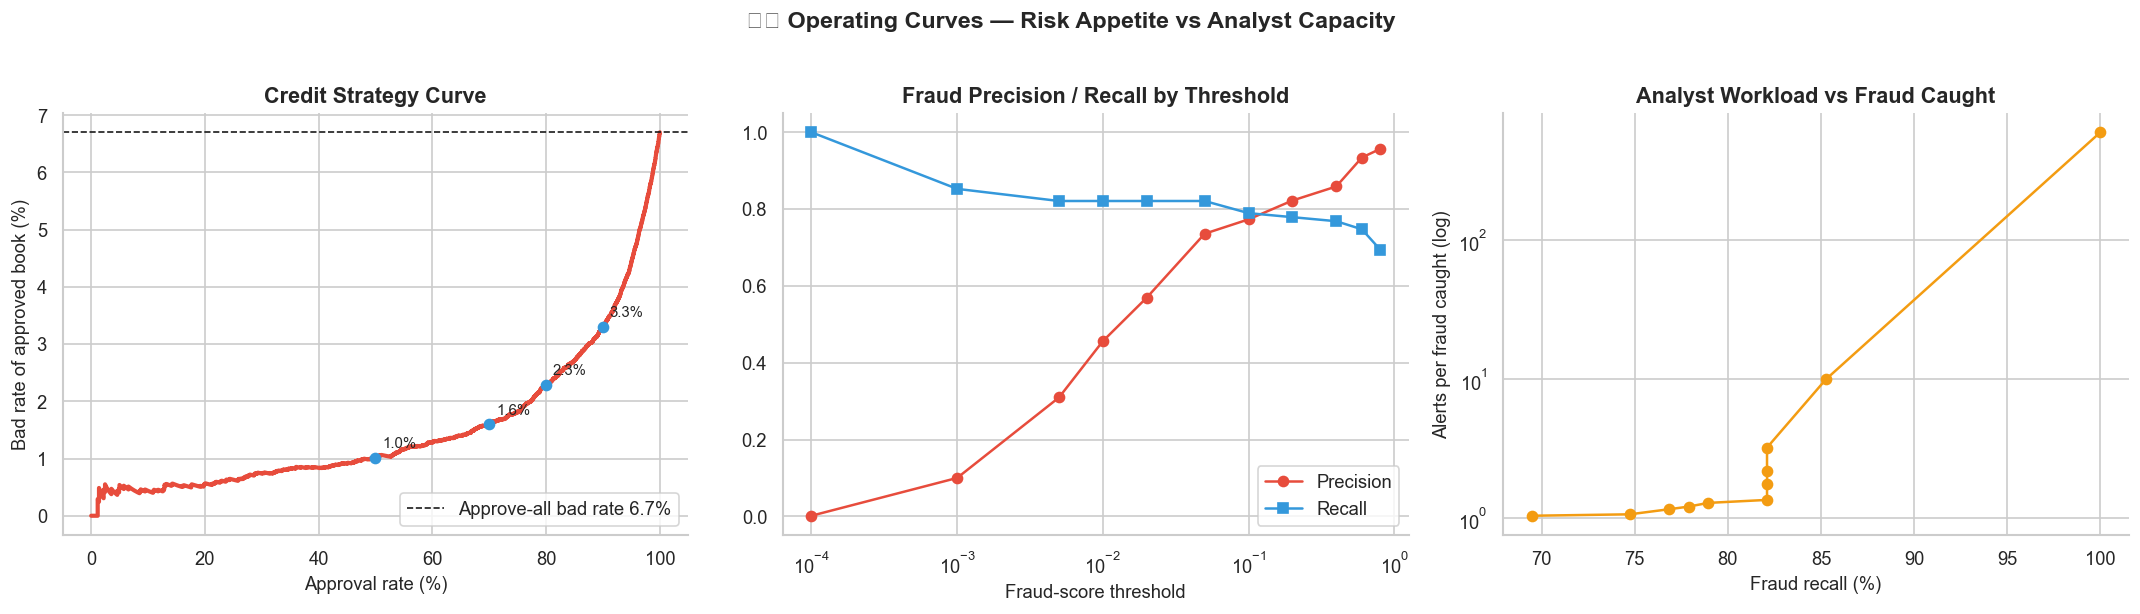

,threshold,alerts,alert_rate_%,precision,recall,alerts_per_fraud_caught
0,0.0001,56739,99.9877,0.0017,1.0000,597.2526
1,0.0010,809,1.4257,0.1001,0.8526,9.9877
2,0.0050,252,0.4441,0.3095,0.8211,3.2308
3,0.0100,171,0.3013,0.4561,0.8211,2.1923
4,0.0200,137,0.2414,0.5693,0.8211,1.7564
5,0.0500,106,0.1868,0.7358,0.8211,1.3590
6,0.1000,97,0.1709,0.7732,0.7895,1.2933
7,0.2000,90,0.1586,0.8222,0.7789,1.2162
8,0.4000,85,0.1498,0.8588,0.7684,1.1644
9,0.6000,76,0.1339,0.9342,0.7474,1.0704


In [6]:
# ── credit strategy curve (hold-out) ──
order = np.argsort(pd_hold)
y_sorted, pd_sorted = yc_hold.values[order], pd_hold[order]
n = len(y_sorted)
approval = np.arange(1, n + 1) / n
bad_rate_approved = np.cumsum(y_sorted) / np.arange(1, n + 1)

# ── fraud threshold table (hold-out) ──
thr = np.array([1e-4, 1e-3, 5e-3, 0.01, 0.02, 0.05, 0.1, 0.2, 0.4, 0.6, 0.8])
rows = []
for t in thr:
    flag = fs_hold >= t
    tp = int((flag & (yf_hold.values == 1)).sum())
    rows.append({"threshold": t, "alerts": int(flag.sum()), "alert_rate_%": flag.mean() * 100,
                 "precision": tp / max(flag.sum(), 1), "recall": tp / yf_hold.sum(),
                 "alerts_per_fraud_caught": flag.sum() / max(tp, 1)})
fthr = pd.DataFrame(rows)

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].plot(approval * 100, bad_rate_approved * 100, color=BAD_COLOR, lw=2.5)
ax[0].axhline(yc_hold.mean() * 100, color="k", ls="--", lw=1, label=f"Approve-all bad rate {yc_hold.mean():.1%}")
for q in (0.5, 0.7, 0.8, 0.9):
    ax[0].scatter(q * 100, bad_rate_approved[int(q * n) - 1] * 100, color=ACCENT_COLOR, zorder=5)
    ax[0].annotate(f"{bad_rate_approved[int(q*n)-1]:.1%}", (q * 100, bad_rate_approved[int(q * n) - 1] * 100), textcoords="offset points", xytext=(4, 6), fontsize=9)
ax[0].set_title("Credit Strategy Curve"); ax[0].set_xlabel("Approval rate (%)"); ax[0].set_ylabel("Bad rate of approved book (%)"); ax[0].legend()

ax[1].plot(fthr["threshold"], fthr["precision"], "o-", color=BAD_COLOR, label="Precision")
ax[1].plot(fthr["threshold"], fthr["recall"], "s-", color=ACCENT_COLOR, label="Recall")
ax[1].set_xscale("log"); ax[1].set_title("Fraud Precision / Recall by Threshold"); ax[1].set_xlabel("Fraud-score threshold"); ax[1].legend()

ax[2].plot(fthr["recall"] * 100, fthr["alerts_per_fraud_caught"], "o-", color=WARN_COLOR)
ax[2].set_yscale("log"); ax[2].set_title("Analyst Workload vs Fraud Caught"); ax[2].set_xlabel("Fraud recall (%)"); ax[2].set_ylabel("Alerts per fraud caught (log)")

plt.suptitle("⚖️ Operating Curves — Risk Appetite vs Analyst Capacity", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()
display(fthr.round(4))

📌 **Observation:**

- **Credit strategy curve:** approving the best 50% of applicants gives a bad rate of **1.0%**, 70% → **1.6%**, 80% → **2.3%**, 90% → **3.3%**, and 100% → 6.7%. The curve is almost flat up to 60% approval and then bends sharply upward: the **riskiest 10% of applicants hold about 56% of all defaults** (6.7 − 0.9 × 3.3 ≈ 3.7 of the 6.7 bad accounts per 100 applicants) and the riskiest 20% hold about 73%.
- **Fraud thresholds (95 hold-out frauds):** at threshold 0.001 → 809 alerts (1.43% of transactions), precision 0.10, recall 0.853; at **0.005 → 252 alerts, precision 0.31; at 0.05 → 106 alerts, precision 0.74** — and recall is **0.821 (78 of 95 frauds) at every threshold from 0.005 to 0.05**. Raising the threshold in that range removes alerts without losing a single fraud.
- Workload plot: **1.36 alerts per fraud caught at 82% recall**, 3.2 at the same recall with threshold 0.005, ≈ 10 at 85% recall and **597 at 100% recall**. The last three frauds (82% → 85%) cost about 700 extra alerts; the last 10 cost tens of thousands.

💡 **Pipeline decision:** Credit cut-offs sit in the steep part of the strategy curve (decline the riskiest ~10–20%, review the borderline band). For fraud, the efficient operating region starts at **a threshold of about 0.05** — the cheapest point that keeps the full 82% recall — and anything lower buys a handful of extra frauds at hundreds of alerts each. Step 10 therefore needs fraud thresholds below 0.05 in its grid.

---
## Step 7 — Decision Matrix Design (PD Band × Fraud Band)
---
**Why:** A 3 × 3 matrix is the simplest decision structure that is still auditable: each score is cut into LOW / MEDIUM / HIGH bands and every cell maps to one action. Compared with a blended "combined score", a matrix keeps the **reason** for each decision visible — essential for adverse-action notices and analyst workflows.  

**Business insight:** The two risks demand different responses. High fraud risk is a **security** decision (stop regardless of credit quality); high credit risk is an **appetite** decision; medium fraud risk is an **information** problem solved by a human review; medium credit risk is a **pricing** matter that does not need review.

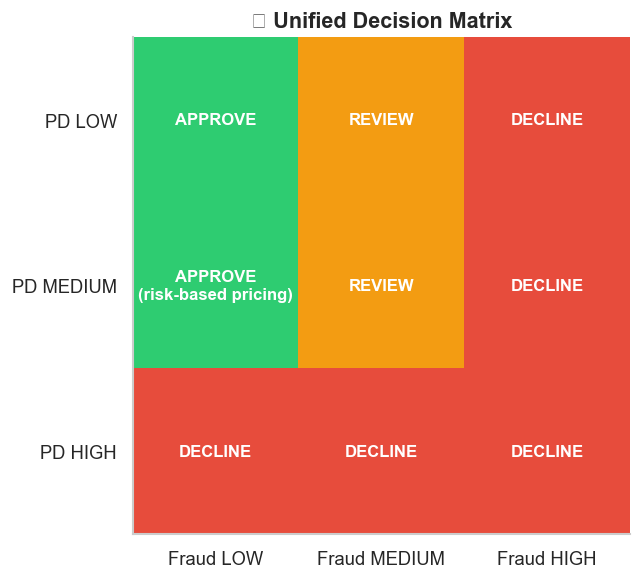

Illustrative applicants (bands: PD ≤ 5% low, ≤ 15% medium; fraud ≤ 2% low, ≤ 50% medium):


,PD,fraud_score,decision,reason_code
0,0.02,0.001,APPROVE,CLEAN
1,0.08,0.002,APPROVE,CLEAN_PRICE_UP
2,0.30,0.003,DECLINE,PD_HIGH
3,0.03,0.150,REVIEW,FRAUD_REVIEW
4,0.10,0.200,REVIEW,FRAUD_REVIEW
5,0.04,0.900,DECLINE,FRAUD_HIGH


In [7]:
# rows = PD band (0 low, 1 medium, 2 high); columns = fraud band (0 low, 1 medium, 2 high)
MATRIX = np.array([[0, 1, 2],     # PD low   : approve | review  | decline
                   [0, 1, 2],     # PD medium: approve (risk-based pricing) | review | decline
                   [2, 2, 2]])    # PD high  : decline in every case

def decide(pd_, fs_, pd_lo, pd_hi, f_lo, f_hi):
    pb = np.where(pd_ <= pd_lo, 0, np.where(pd_ <= pd_hi, 1, 2))
    fb = np.where(fs_ <= f_lo, 0, np.where(fs_ <= f_hi, 1, 2))
    return MATRIX[pb, fb], pb, fb

BAND_NAMES = ["LOW", "MEDIUM", "HIGH"]
fig, ax = plt.subplots(figsize=(7, 5))
ax.imshow(MATRIX, cmap=plt.matplotlib.colors.ListedColormap([GOOD_COLOR, WARN_COLOR, BAD_COLOR]), vmin=0, vmax=2)
for i in range(3):
    for j in range(3):
        label = DEC_NAMES[MATRIX[i, j]] + ("\n(risk-based pricing)" if (i == 1 and j == 0) else "")
        ax.text(j, i, label, ha="center", va="center", fontweight="bold", color="white", fontsize=10)
ax.set_xticks(range(3)); ax.set_xticklabels([f"Fraud {b}" for b in BAND_NAMES])
ax.set_yticks(range(3)); ax.set_yticklabels([f"PD {b}" for b in BAND_NAMES])
ax.set_title("🧭 Unified Decision Matrix"); ax.grid(False)
plt.tight_layout(); plt.show()

REASONS = {(0, 0): "CLEAN", (0, 1): "FRAUD_REVIEW", (0, 2): "FRAUD_HIGH", (1, 0): "CLEAN_PRICE_UP", (1, 1): "FRAUD_REVIEW",
           (1, 2): "FRAUD_HIGH", (2, 0): "PD_HIGH", (2, 1): "PD_HIGH", (2, 2): "PD_HIGH+FRAUD_HIGH"}
demo = pd.DataFrame({"PD": [0.02, 0.08, 0.30, 0.03, 0.10, 0.04], "fraud_score": [0.001, 0.002, 0.003, 0.15, 0.20, 0.90]})
d_, pb_, fb_ = decide(demo["PD"].values, demo["fraud_score"].values, 0.05, 0.15, 0.02, 0.50)
demo["decision"] = [DEC_NAMES[v] for v in d_]
demo["reason_code"] = [REASONS[(p, f)] for p, f in zip(pb_, fb_)]
print("Illustrative applicants (bands: PD ≤ 5% low, ≤ 15% medium; fraud ≤ 2% low, ≤ 50% medium):")
display(demo)

📌 **Observation:**

- The matrix has three zones: a green corner (low fraud with low or medium PD → APPROVE), a red column and row (high fraud *or* high PD → DECLINE) and an amber middle column (medium fraud → REVIEW unless PD is already high).
- The six illustrative applicants show the logic: PD 0.02 / fraud 0.001 → **APPROVE (`CLEAN`)**; PD 0.08 / fraud 0.002 → **APPROVE (`CLEAN_PRICE_UP`)**; PD 0.30 / fraud 0.003 → **DECLINE (`PD_HIGH`)**; PD 0.03 / fraud 0.15 and PD 0.10 / fraud 0.20 → **REVIEW (`FRAUD_REVIEW`)**; PD **0.04** / fraud **0.90** → **DECLINE (`FRAUD_HIGH`)** — an applicant with an excellent credit profile is stopped purely by the fraud score.
- Every outcome carries a reason code, so a decline can be explained as a credit decision or as a fraud decision.

💡 **Pipeline decision:** `decision_engine()` implements the matrix as a **lookup**, not a blended score; the band cut-offs (`pd_lo`, `pd_hi`, `f_lo`, `f_hi`) come from Step 10 and live in versioned config. The reason code is returned by the API and logged for monitoring. Hard-policy overrides sit outside the model in a separate rule layer. Step 10 shows that, with this fraud score, the REVIEW column is almost empty in practice.

---
## Step 8 — Simulated Application Portfolio
---
**Why:** Because no dataset contains both a credit history and a fraud score for the same person, an application portfolio is **simulated**: credit hold-out applicants are paired with fraud-scored records. Two portfolios are built from *disjoint halves* of the hold-out data — a **tuning** portfolio (to choose thresholds) and an **evaluation** portfolio (to report results) — so thresholds are never judged on the data that selected them.  

**Business insight:** Application fraud is far more prevalent than transaction fraud (0.17%), so the fraud pool is re-sampled to an **assumed application-level prevalence** and the fraud probabilities are **prior-shift corrected** — otherwise a score calibrated at 0.17% prevalence would badly understate risk in a 1% world.

,applicants,default rate %,fraud rate %,"corr(PD, fraud score)"
tuning,14939,6.7006,0.9974,0.0052
evaluation,14940,6.7001,0.9973,0.0069


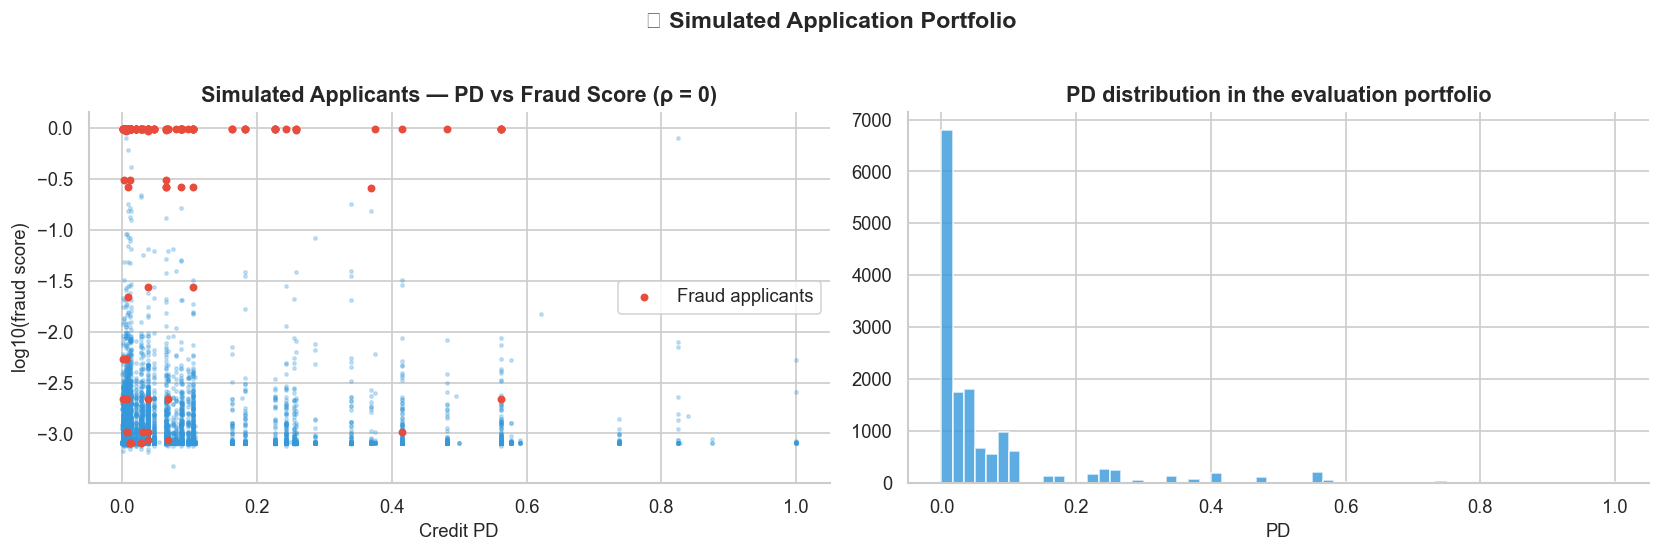

In [8]:
def prior_shift(p, pi_old, pi_new):
    """Re-express a probability calibrated at prevalence pi_old for a population with prevalence pi_new."""
    r1, r0 = pi_new / pi_old, (1 - pi_new) / (1 - pi_old)
    return p * r1 / (p * r1 + (1 - p) * r0)

# disjoint tuning / evaluation halves of BOTH hold-out sets
credit_hold_df = pd.DataFrame({"pd": pd_hold, "y_def": yc_hold.values, "age": c_hold["age"].where(c_hold["age"] >= 18, AGE_MEDIAN).values})
fraud_hold_df  = pd.DataFrame({"fs": fs_hold, "y_fraud": yf_hold.values})
c_tune, c_eval = train_test_split(credit_hold_df, test_size=0.5, stratify=credit_hold_df["y_def"], random_state=SEED)
f_tune, f_eval = train_test_split(fraud_hold_df,  test_size=0.5, stratify=fraud_hold_df["y_fraud"], random_state=SEED)

def build_portfolio(credit_df, fraud_df, rho=0.0, seed=0, fraud_rate=APP_FRAUD_RATE):
    """Pair each credit applicant with one fraud-scored record.
       rho = rank correlation between PD and fraud score (0 = independent)."""
    rng = np.random.default_rng(seed)
    n = len(credit_df)
    n_f = int(round(n * fraud_rate))
    fr = fraud_df[fraud_df["y_fraud"] == 1].sample(n_f, replace=True, random_state=seed)     # bootstrap: few real frauds
    lg = fraud_df[fraud_df["y_fraud"] == 0].sample(n - n_f, replace=True, random_state=seed)
    pool = pd.concat([fr, lg]).copy()
    pool["fs"] = prior_shift(pool["fs"].values, FRAUD_PRIOR, fraud_rate)
    pool = pool.sort_values("fs").reset_index(drop=True)

    c = credit_df.reset_index(drop=True).copy()
    z = stats.norm.ppf((stats.rankdata(c["pd"]) - 0.5) / n)
    key = rho * z + np.sqrt(1 - rho ** 2) * rng.normal(size=n)
    idx = stats.rankdata(key, method="ordinal").astype(int) - 1       # permutation: high key → high fraud score
    c["fs"], c["y_fraud"] = pool.loc[idx, "fs"].values, pool.loc[idx, "y_fraud"].values
    return c

port_tune = build_portfolio(c_tune, f_tune, rho=0.0, seed=1)
port_eval = build_portfolio(c_eval, f_eval, rho=0.0, seed=2)

summary = pd.DataFrame({
    "applicants": [len(port_tune), len(port_eval)],
    "default rate %": [port_tune.y_def.mean() * 100, port_eval.y_def.mean() * 100],
    "fraud rate %": [port_tune.y_fraud.mean() * 100, port_eval.y_fraud.mean() * 100],
    "corr(PD, fraud score)": [port_tune[["pd", "fs"]].corr(method="spearman").iloc[0, 1], port_eval[["pd", "fs"]].corr(method="spearman").iloc[0, 1]],
}, index=["tuning", "evaluation"])
display(summary.round(4))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].scatter(port_eval["pd"], np.log10(port_eval["fs"]), s=4, alpha=0.25, color=ACCENT_COLOR)
fraud_pts = port_eval[port_eval.y_fraud == 1]
ax[0].scatter(fraud_pts["pd"], np.log10(fraud_pts["fs"]), s=14, color=BAD_COLOR, label="Fraud applicants")
ax[0].set_xlabel("Credit PD"); ax[0].set_ylabel("log10(fraud score)"); ax[0].set_title("Simulated Applicants — PD vs Fraud Score (ρ = 0)"); ax[0].legend()
ax[1].hist(port_eval["pd"], bins=60, color=ACCENT_COLOR, alpha=0.8); ax[1].set_title("PD distribution in the evaluation portfolio"); ax[1].set_xlabel("PD")
plt.suptitle("🧪 Simulated Application Portfolio", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

📌 **Observation:**

- The two portfolios have the intended composition: **14,939 tuning and 14,940 evaluation applicants**, default rate **6.70%** in both, fraud rate **0.997%** (assumed 1%) and a PD–fraud-score rank correlation of **0.005 / 0.007** — independent by construction.
- Scatter plot: the fraud applicants (red) form a row at the very top (log10 score ≈ 0, i.e. fraud score ≈ 1) **spread over the whole PD range from ≈ 0 to 0.56**, including the lowest-PD region. A second group sits at mid scores (log10 ≈ −0.5 to −1.6), and a few red points lie at the score floor (≈ −2.3 to −3.1), invisible to the model. These are fraudsters who look like perfectly good credit risks.
- PD histogram: about **6,800 of 14,940 applicants (≈ 45%) have PD ≤ 0.02**, with a long thin tail and visible isotonic steps up to 1.0.
- The 1% fraud pool is bootstrapped from only ~47 real frauds per half, so the same records recur — fraud results are correspondingly noisy.

💡 **Pipeline decision:** The simulation is a **design and validation tool only** and is replaced by real joined application data (credit-bureau pull + identity / device / behavioural signals per applicant) as soon as the platform collects it. `APP_FRAUD_RATE` becomes an observed parameter, and the prior-shift correction stays in the scoring service so the fraud score remains calibrated to the live application mix.

---
## Step 9 — Economic Model and Policy Evaluation
---
**Why:** AUC and accuracy cannot choose a threshold, because errors have very different prices. A **profit function** turns every decision into money: margin on good loans, loss on defaults, larger loss on approved fraud, and a fixed cost per review. Manual review is modelled as an imperfect analyst who catches most fraud and half of the bad credits, and wrongly declines a small share of good cases.  

**Business insight:** The right question for the credit committee is "which policy earns the most after losses and review costs?" — and "what does each policy cost us in fraud losses versus lost margin?" Both answers come from the same function.

In [9]:
def evaluate(decision, y_def, y_fraud, seed=0):
    """decision: 0 approve / 1 review / 2 decline.  Returns profit components (in $)."""
    decision, y_def, y_fraud = map(np.asarray, (decision, y_def, y_fraud))
    n = len(decision)
    rng = np.random.default_rng(seed)
    review = decision == 1
    caught_f, caught_c, false_dec = rng.random(n) < REVIEW_FRAUD_CATCH, rng.random(n) < REVIEW_CREDIT_CATCH, rng.random(n) < REVIEW_FALSE_DECLINE
    rev_decline = review & (((y_fraud == 1) & caught_f) | ((y_def == 1) & caught_c) | false_dec)
    final_approve = (decision == 0) | (review & ~rev_decline)

    fraud_loss  = (final_approve & (y_fraud == 1)).sum() * LOAN_AMOUNT * FRAUD_LOSS_RATE
    credit_loss = (final_approve & (y_fraud == 0) & (y_def == 1)).sum() * LOAN_AMOUNT * LGD
    revenue     = (final_approve & (y_fraud == 0) & (y_def == 0)).sum() * LOAN_AMOUNT * MARGIN_RATE
    review_cost = review.sum() * REVIEW_COST
    profit = revenue - credit_loss - fraud_loss - review_cost
    return {"profit": profit, "profit_per_applicant": profit / n, "revenue": revenue, "credit_loss": credit_loss,
            "fraud_loss": fraud_loss, "review_cost": review_cost,
            "approve_%": (decision == 0).mean() * 100, "review_%": review.mean() * 100, "decline_%": (decision == 2).mean() * 100,
            "final_approval_%": final_approve.mean() * 100,
            "default_rate_approved_%": (y_def[final_approve].mean() * 100) if final_approve.any() else np.nan,
            "fraud_rate_approved_%": (y_fraud[final_approve].mean() * 100) if final_approve.any() else np.nan}

# sanity benchmarks on the tuning portfolio
bench = pd.DataFrame({
    "approve everyone": evaluate(np.zeros(len(port_tune), int), port_tune.y_def, port_tune.y_fraud),
    "decline everyone": evaluate(np.full(len(port_tune), 2), port_tune.y_def, port_tune.y_fraud),
    "review everyone":  evaluate(np.ones(len(port_tune), int), port_tune.y_def, port_tune.y_fraud),
}).T
display(bench[["profit_per_applicant", "revenue", "credit_loss", "fraud_loss", "review_cost", "final_approval_%"]].round(1))

,profit_per_applicant,revenue,credit_loss,fraud_loss,review_cost,final_approval_%
approve everyone,241.6,11040000.0,5940000.0,1490000.0,0.0,100.0
decline everyone,0.0,0.0,0.0,0.0,0.0,0.0
review everyone,441.3,9908000.0,2742000.0,200000.0,373475.0,86.1


📌 **Observation:**

On the tuning portfolio (14,939 applicants):

| Benchmark | Profit per applicant | Revenue | Credit loss | Fraud loss | Review cost |
|---|---|---|---|---|---|
| Approve everyone | **$241.6** | $11.04M | $5.94M | $1.49M | $0 |
| Decline everyone | **$0** | $0 | $0 | $0 | $0 |
| Review everyone | **$441.3** | $9.91M | $2.74M | $0.20M | $0.37M |

- Approving everyone earns $242 per applicant because losses consume a large share of the margin: about **$397 per applicant in credit losses and $100 in fraud losses** against ≈ $740 of revenue.
- **Reviewing everyone almost doubles the profit ($441)**: it cuts credit losses by 54% and fraud losses by 87%, costs $373k in review fees, and only 86.1% of applicants end up approved. The reason is the generous analyst accuracy assumed in Step 1 (85% of fraud and 50% of defaults caught for $25).
- Any useful policy has to beat **$441**, which is a much higher bar than approve-all.

💡 **Pipeline decision:** `evaluate()` becomes the shared objective for threshold tuning, champion-challenger comparison and the monthly business report — model changes are judged in **profit per applicant** next to AUC / KS. The three analyst parameters (`REVIEW_FRAUD_CATCH`, `REVIEW_CREDIT_CATCH`, `REVIEW_FALSE_DECLINE`) are the most sensitive inputs in the whole notebook and must be calibrated from real review outcomes; the quarterly refresh of cost inputs includes them.

---
## Step 10 — Threshold Optimisation on the Tuning Portfolio
---
**Why:** Thresholds are chosen by a **grid search that maximises profit on the tuning portfolio only**. The heatmap shows the whole profit surface, so the team sees how flat or sharp the optimum is — a flat surface means the rule is robust to small errors, a sharp peak means it is fragile. Single-model policies (credit-only, fraud-only) are tuned on the same data for a fair comparison.  

**Business insight:** The choice is a three-way trade-off — **approval volume** (growth), **loss** (risk) and **review workload** (operations capacity). Seeing the grid lets the business pick an operating point deliberately, not just the mathematical maximum.

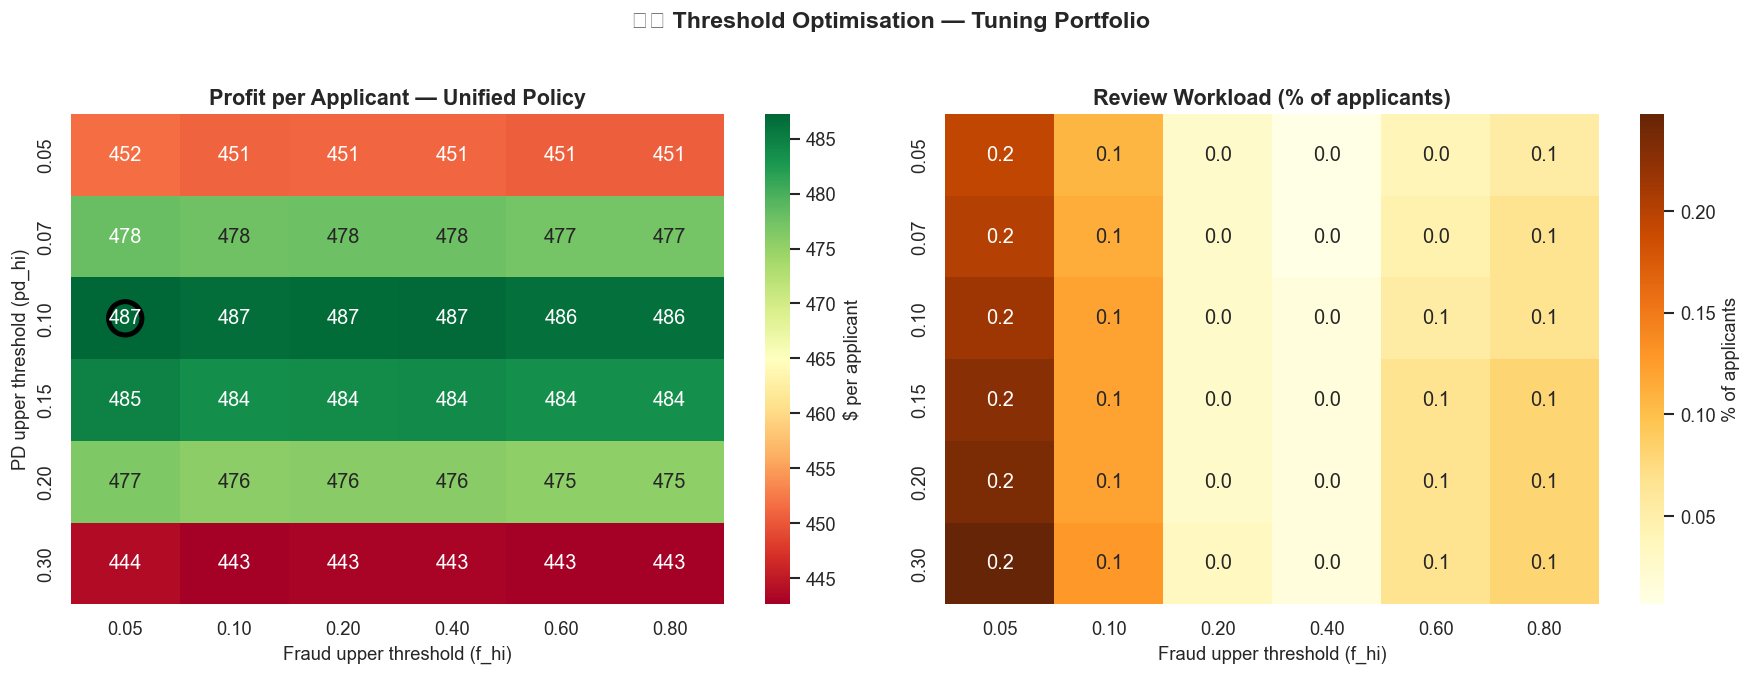

Best unified thresholds  : pd_hi = 0.10 (pd_lo = 0.050),  f_hi = 0.05 (f_lo = 0.020)
Best credit-only cut-off : PD > 0.10
Best fraud-only cut-off  : fraud score > 0.02


In [10]:
PD_HI_GRID = [0.05, 0.07, 0.10, 0.15, 0.20, 0.30]
F_HI_GRID  = [0.05, 0.10, 0.20, 0.40, 0.60, 0.80]
PD_LO_RATIO, F_LO_RATIO = 0.5, 0.4          # lower band edge as a fraction of the upper edge

def run_unified(port, pd_hi, f_hi):
    d, _, _ = decide(port["pd"].values, port["fs"].values, PD_LO_RATIO * pd_hi, pd_hi, F_LO_RATIO * f_hi, f_hi)
    return evaluate(d, port["y_def"], port["y_fraud"])

grid_profit = pd.DataFrame(index=[f"{v:.2f}" for v in PD_HI_GRID], columns=[f"{v:.2f}" for v in F_HI_GRID], dtype=float)
grid_review = grid_profit.copy()
for p_hi in PD_HI_GRID:
    for f_hi in F_HI_GRID:
        r = run_unified(port_tune, p_hi, f_hi)
        grid_profit.loc[f"{p_hi:.2f}", f"{f_hi:.2f}"] = r["profit_per_applicant"]
        grid_review.loc[f"{p_hi:.2f}", f"{f_hi:.2f}"] = r["review_%"]

best_idx = np.unravel_index(np.nanargmax(grid_profit.values), grid_profit.shape)
BEST_PD_HI, BEST_F_HI = PD_HI_GRID[best_idx[0]], F_HI_GRID[best_idx[1]]

# single-model policies tuned on the same tuning portfolio
credit_only_grid = {t: evaluate(np.where(port_tune["pd"] > t, 2, 0), port_tune.y_def, port_tune.y_fraud)["profit_per_applicant"]
                    for t in [0.03, 0.05, 0.07, 0.10, 0.15, 0.20, 0.30, 0.50]}
fraud_only_grid  = {t: evaluate(np.where(port_tune["fs"] > t, 2, 0), port_tune.y_def, port_tune.y_fraud)["profit_per_applicant"]
                    for t in [0.02, 0.05, 0.10, 0.20, 0.40, 0.60, 0.80]}
BEST_T_CREDIT, BEST_T_FRAUD = max(credit_only_grid, key=credit_only_grid.get), max(fraud_only_grid, key=fraud_only_grid.get)

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(grid_profit, annot=True, fmt=".0f", cmap="RdYlGn", ax=ax[0], cbar_kws={"label": "$ per applicant"})
ax[0].scatter(best_idx[1] + 0.5, best_idx[0] + 0.5, s=400, facecolors="none", edgecolors="black", linewidths=3)
ax[0].set_title("Profit per Applicant — Unified Policy"); ax[0].set_xlabel("Fraud upper threshold (f_hi)"); ax[0].set_ylabel("PD upper threshold (pd_hi)")
sns.heatmap(grid_review, annot=True, fmt=".1f", cmap="YlOrBr", ax=ax[1], cbar_kws={"label": "% of applicants"})
ax[1].set_title("Review Workload (% of applicants)"); ax[1].set_xlabel("Fraud upper threshold (f_hi)"); ax[1].set_ylabel("")
plt.suptitle("🎛️ Threshold Optimisation — Tuning Portfolio", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

print(f"Best unified thresholds  : pd_hi = {BEST_PD_HI:.2f} (pd_lo = {PD_LO_RATIO*BEST_PD_HI:.3f}),  f_hi = {BEST_F_HI:.2f} (f_lo = {F_LO_RATIO*BEST_F_HI:.3f})")
print(f"Best credit-only cut-off : PD > {BEST_T_CREDIT:.2f}")
print(f"Best fraud-only cut-off  : fraud score > {BEST_T_FRAUD:.2f}")

📌 **Observation:**

- Profit heatmap: moving down the rows (the PD threshold) changes profit a lot — **$451–452** at pd_hi 0.05, $477–478 at 0.07, **$486–487 at 0.10 (best)**, $484–485 at 0.15, $475–477 at 0.20 and only **$443–444 at 0.30**. The optimum is a plateau between pd_hi 0.10 and 0.15 (within $3).
- Moving across the columns (the fraud threshold, 0.05 → 0.80) changes profit by **at most about $2**. Because the fraud score is bimodal (Step 5), every threshold in this grid gives practically the same decisions; the selected point is **pd_hi = 0.10, f_hi = 0.05** ($487 per applicant on the tuning portfolio).
- Review workload heatmap: the REVIEW share never exceeds **0.2% of applicants** (maximum at f_hi = 0.05, where the medium fraud band is 0.02–0.05) and is ≈ 0.0% for f_hi of 0.2–0.4.
- Single-model policies tuned on the same data: credit-only cut-off **PD > 0.10**, fraud-only cut-off **fraud score > 0.02**.

💡 **Pipeline decision:**

- Select **pd_hi = 0.10 (pd_lo = 0.05)** and **f_hi = 0.05 (f_lo = 0.02)**, stored in versioned config; re-run the grid monthly with a plateau check.
- ⚠️ **Review item:** the fraud grid starts at 0.05, exactly where Step 6 shows the efficient region ends, so it cannot resolve the real trade-off between 0.001 and 0.05. Extend it (0.002, 0.005, 0.01, 0.02) and replace the fixed `f_lo = 0.4 × f_hi` ratio with a **capacity-constrained REVIEW band** (best profit subject to `review_% ≤ analyst capacity`) — with today's grid REVIEW is effectively unused.

---
## Step 11 — Policy Comparison on the Unseen Evaluation Portfolio
---
**Why:** The thresholds chosen in Step 10 are now applied **unchanged** to the evaluation portfolio, which played no part in selecting them. Comparing five policies — approve-all, credit-only, fraud-only, review-all and unified — on identical applicants isolates the value of combining the two scores. A stacked decomposition shows *where* the profit comes from.  

**Business insight:** The case for the unified engine is a number: how much more profit per applicant does it earn than the best single-model alternative, and where does the gain come from — fewer fraud losses, fewer credit losses or fewer lost good customers?

,profit_per_applicant,revenue,credit_loss,fraud_loss,review_cost,approve_%,review_%,decline_%,final_approval_%,default_rate_approved_%,fraud_rate_approved_%
Approve all,243.05,11043200.0,5922000.0,1490000.0,0.0,100.00,0.00,0.00,100.00,6.70,1.00
Credit-only,443.75,9697600.0,1878000.0,1190000.0,0.0,84.03,0.00,15.97,84.03,2.53,0.95
Fraud-only,329.26,10991200.0,5892000.0,180000.0,0.0,98.65,0.00,1.35,98.65,6.67,0.12
Review all,442.23,9894400.0,2754000.0,160000.0,373500.0,0.00,100.00,0.00,85.96,3.59,0.12
Unified matrix,511.49,9674400.0,1872000.0,160000.0,700.0,82.98,0.19,16.83,83.14,2.52,0.13


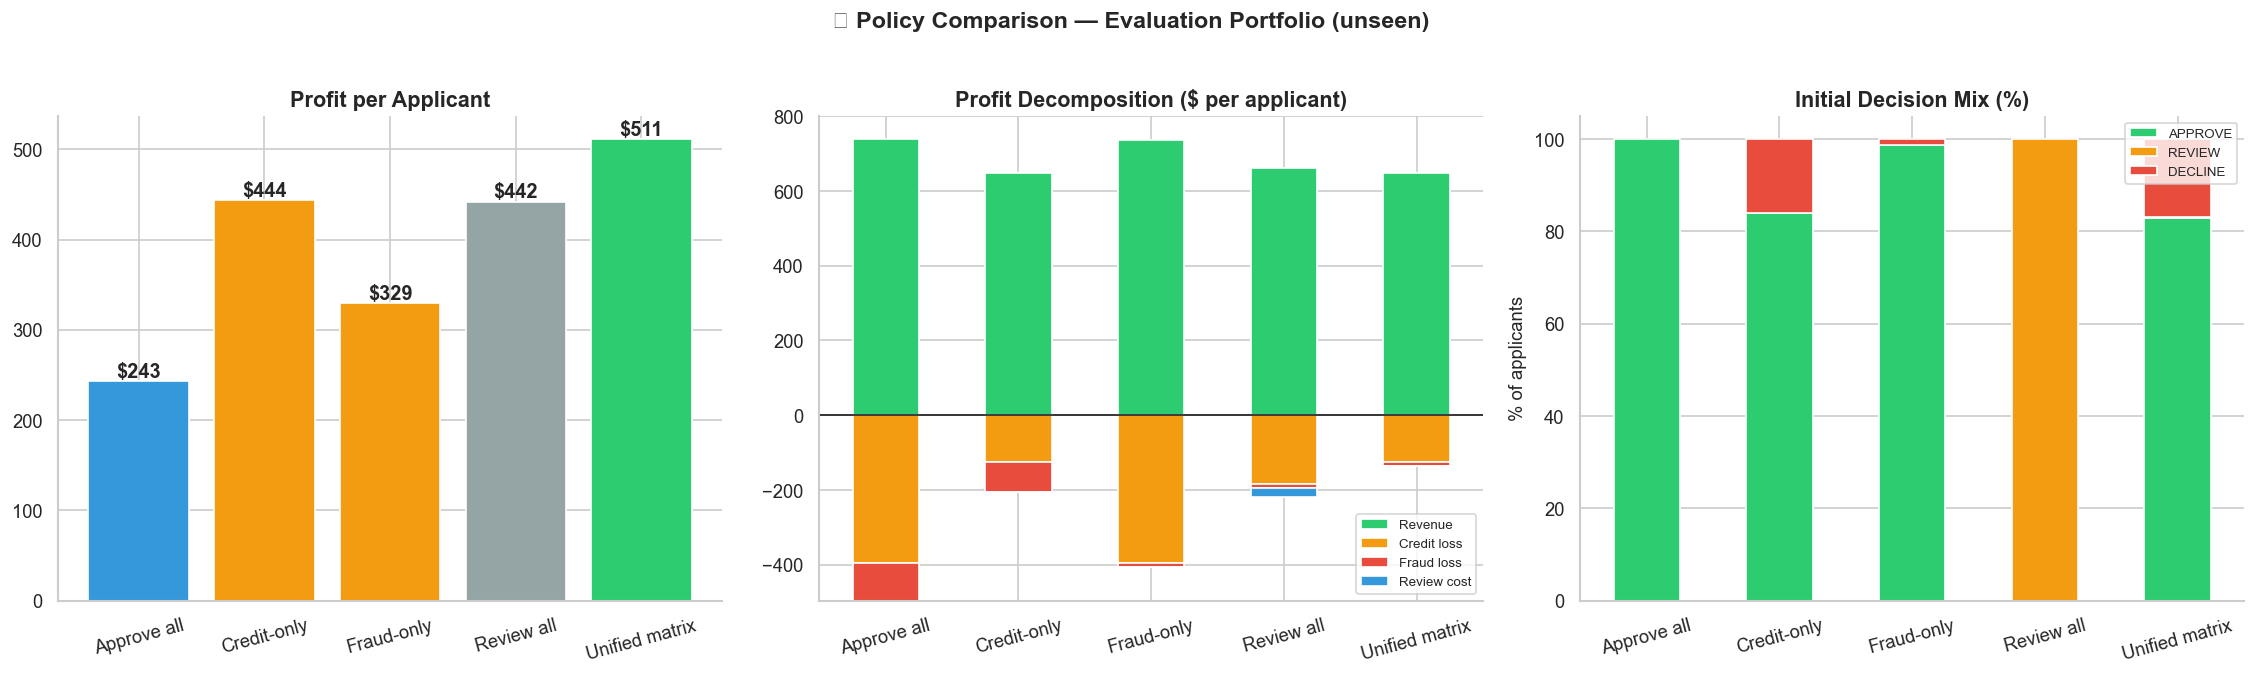

Unified vs best single-model policy: +67.7 $ per applicant  (+1,012,100 $ on 14,940 applicants)


In [11]:
def policy_table(port):
    d_unified, _, _ = decide(port["pd"].values, port["fs"].values, PD_LO_RATIO * BEST_PD_HI, BEST_PD_HI, F_LO_RATIO * BEST_F_HI, BEST_F_HI)
    decisions = {"Approve all": np.zeros(len(port), int),
                 "Credit-only": np.where(port["pd"] > BEST_T_CREDIT, 2, 0),
                 "Fraud-only":  np.where(port["fs"] > BEST_T_FRAUD, 2, 0),
                 "Review all": np.ones(len(port), int),
                 "Unified matrix": d_unified}
    return pd.DataFrame({k: evaluate(v, port.y_def, port.y_fraud) for k, v in decisions.items()}).T, decisions

pol, decisions_eval = policy_table(port_eval)
display(pol[["profit_per_applicant", "revenue", "credit_loss", "fraud_loss", "review_cost",
             "approve_%", "review_%", "decline_%", "final_approval_%", "default_rate_approved_%", "fraud_rate_approved_%"]].round(2))

fig, ax = plt.subplots(1, 3, figsize=(19, 5.5))
colors = [ACCENT_COLOR, WARN_COLOR, WARN_COLOR, "#95A5A6", GOOD_COLOR]
ax[0].bar(pol.index, pol["profit_per_applicant"], color=colors, edgecolor="white")
for i, v in enumerate(pol["profit_per_applicant"]): ax[0].text(i, v, f"${v:,.0f}", ha="center", va="bottom", fontweight="bold")
ax[0].set_title("Profit per Applicant"); ax[0].tick_params(axis="x", rotation=15)

n_eval = len(port_eval)
comp = pd.DataFrame({"Revenue": pol["revenue"], "Credit loss": -pol["credit_loss"], "Fraud loss": -pol["fraud_loss"], "Review cost": -pol["review_cost"]}) / n_eval
comp[["Revenue"]].plot.bar(ax=ax[1], color=GOOD_COLOR, stacked=True, legend=False, rot=15)
comp[["Credit loss", "Fraud loss", "Review cost"]].plot.bar(ax=ax[1], color=[WARN_COLOR, BAD_COLOR, ACCENT_COLOR], stacked=True, rot=15)
ax[1].axhline(0, color="k", lw=1); ax[1].set_title("Profit Decomposition ($ per applicant)"); ax[1].legend(fontsize=8)

dec_share = pd.DataFrame({k: pd.Series(v).value_counts(normalize=True).reindex([0, 1, 2], fill_value=0) * 100 for k, v in decisions_eval.items()}).T
dec_share.columns = [DEC_NAMES[c] for c in dec_share.columns]
dec_share.plot.bar(stacked=True, color=[GOOD_COLOR, WARN_COLOR, BAD_COLOR], ax=ax[2], rot=15)
ax[2].set_title("Initial Decision Mix (%)"); ax[2].set_ylabel("% of applicants"); ax[2].legend(fontsize=8)

plt.suptitle("🏆 Policy Comparison — Evaluation Portfolio (unseen)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

gain = pol.loc["Unified matrix", "profit_per_applicant"] - max(pol.loc["Credit-only", "profit_per_applicant"], pol.loc["Fraud-only", "profit_per_applicant"])
print(f"Unified vs best single-model policy: {gain:+,.1f} $ per applicant  ({gain * n_eval:+,.0f} $ on {n_eval:,} applicants)")

📌 **Observation:**

On the unseen evaluation portfolio (14,940 applicants):

| Policy | Profit / applicant | Credit loss | Fraud loss | Review cost | Final approval | Default rate of approved | Fraud rate of approved |
|---|---|---|---|---|---|---|---|
| Approve all | $243.05 | $5.92M | $1.49M | $0 | 100% | 6.70% | 1.00% |
| Credit-only | $443.75 | $1.88M | $1.19M | $0 | 84.0% | 2.53% | 0.95% |
| Fraud-only | $329.26 | $5.89M | $0.18M | $0 | 98.7% | 6.67% | 0.12% |
| Review all | $442.23 | $2.75M | $0.16M | $373.5k | 86.0% | 3.59% | 0.12% |
| **Unified matrix** | **$511.49** | $1.87M | **$0.16M** | **$700** | 83.1% | 2.52% | **0.13%** |

- The unified rule earns **$67.7 more per applicant than the best single-model policy (credit-only) — about $1.01M on 14,940 applicants**.
- The decomposition shows where it comes from: credit losses are the same as credit-only ($1.87M vs $1.88M) but **fraud losses fall from $1.19M to $0.16M (−87%)**, because 0.86 percentage points more applicants are declined (16.83% vs 15.97%, ≈ 128 applicants) — most of them fraudsters with good-looking PD.
- Credit-only still approves fraud at a 0.95% rate (against a 1% base rate), confirming that a credit model is blind to fraud; fraud-only removes fraud but keeps the full credit loss.
- **Review all ($442) earns about the same as credit-only ($444)** at a cost of $373.5k in review fees; the unified rule uses just **0.19% reviews (≈ 28 cases, $700)**, so almost all of its advantage comes from DECLINE decisions, not from reviews.

💡 **Pipeline decision:** The platform ships the **unified matrix** as champion, with credit-only and fraud-only rules kept as shadow challengers in the monitoring dashboard. Because the 1% fraud pool is bootstrapped from about 47 real frauds, the +$68 figure is reported with a **bootstrap confidence interval** before it is quoted to the business and is treated as indicative until real joined data replaces the simulation.

---
## Step 12 — Dependence Stress Test (Credit–Fraud Correlation)
---
**Why:** Steps 8–11 assumed credit risk and fraud risk are **independent**, which the data could not contradict. Real portfolios usually are not: a fraudster using a stolen identity may show a thin or inconsistent credit file, and synthetic identities often have unusual credit features. The portfolio is rebuilt with a controlled rank correlation ρ between PD and fraud score, and the thresholds tuned at ρ = 0 are applied unchanged — the same procedure as a model-risk stress test. A second table varies the cost assumptions.  

**Business insight:** The decision engine must not depend on a hidden assumption that no one can verify. If the unified policy keeps its advantage across plausible ρ and cost values, the conclusion is robust; if it collapses somewhere, that region needs a specific control.

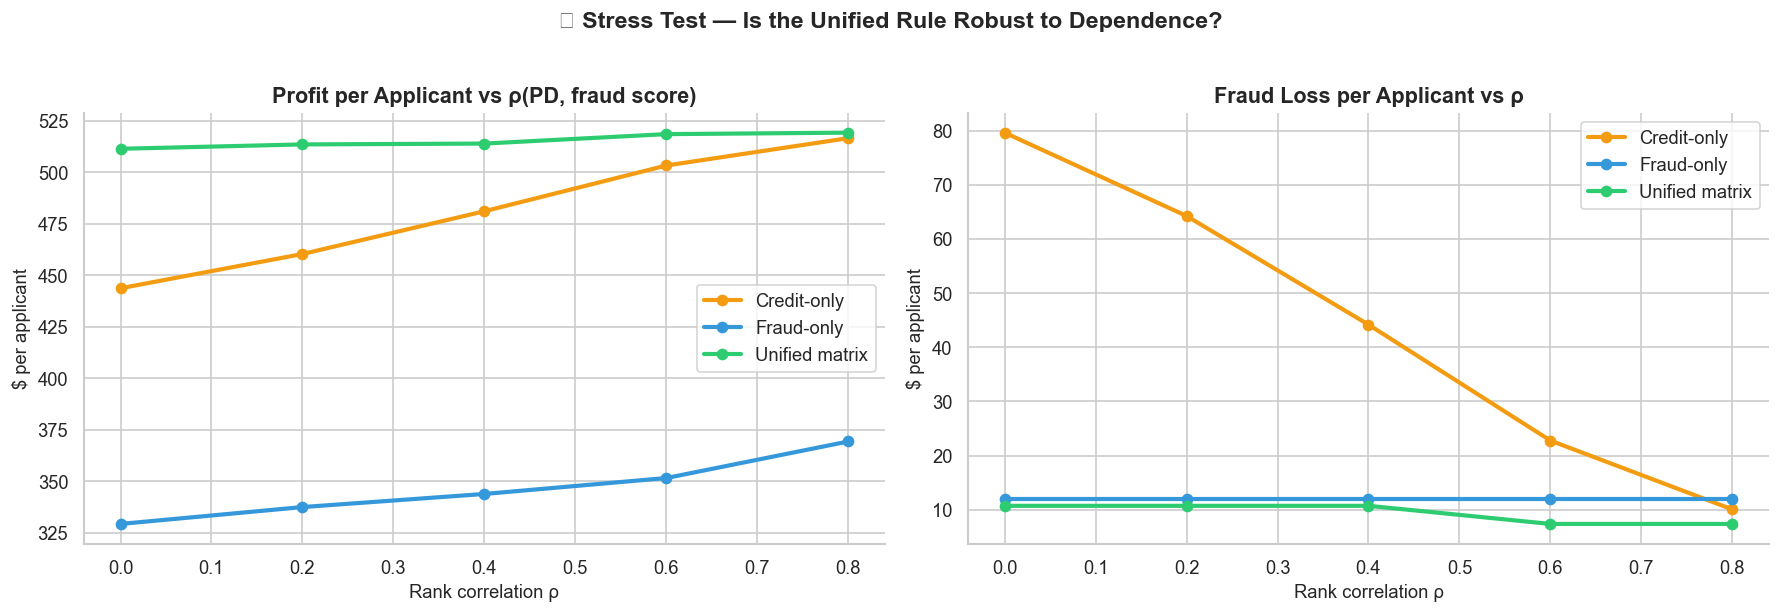

fraud loss ×,0.5,1.0,1.5
LGD ×,,,
0.5,33.1,67.5,102.0
1.0,33.3,67.7,102.2
1.5,33.5,67.9,102.4


In [12]:
rhos = [0.0, 0.2, 0.4, 0.6, 0.8]
rows = []
for rho in rhos:
    p = build_portfolio(c_eval, f_eval, rho=rho, seed=2)
    pol_r, _ = policy_table(p)
    for name in ["Credit-only", "Fraud-only", "Unified matrix"]:
        rows.append({"rho": rho, "policy": name, "profit_per_applicant": pol_r.loc[name, "profit_per_applicant"],
                     "fraud_loss": pol_r.loc[name, "fraud_loss"] / len(p), "review_%": pol_r.loc[name, "review_%"]})
stress = pd.DataFrame(rows)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for name, col in [("Credit-only", WARN_COLOR), ("Fraud-only", ACCENT_COLOR), ("Unified matrix", GOOD_COLOR)]:
    s = stress[stress.policy == name]
    ax[0].plot(s["rho"], s["profit_per_applicant"], "o-", color=col, lw=2.5, label=name)
    ax[1].plot(s["rho"], s["fraud_loss"], "o-", color=col, lw=2.5, label=name)
ax[0].set_title("Profit per Applicant vs ρ(PD, fraud score)"); ax[0].set_xlabel("Rank correlation ρ"); ax[0].set_ylabel("$ per applicant"); ax[0].legend()
ax[1].set_title("Fraud Loss per Applicant vs ρ"); ax[1].set_xlabel("Rank correlation ρ"); ax[1].set_ylabel("$ per applicant"); ax[1].legend()
plt.suptitle("🧨 Stress Test — Is the Unified Rule Robust to Dependence?", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

# cost-sensitivity: scale LGD and fraud-loss assumptions, keep thresholds fixed
sens_rows = []
for lgd_mult in (0.5, 1.0, 1.5):
    for loss_mult in (0.5, 1.0, 1.5):
        base_lgd, base_fl = LGD, FRAUD_LOSS_RATE
        LGD, FRAUD_LOSS_RATE = base_lgd * lgd_mult, base_fl * loss_mult
        p_s, _ = policy_table(port_eval)
        LGD, FRAUD_LOSS_RATE = base_lgd, base_fl
        sens_rows.append({"LGD ×": lgd_mult, "fraud loss ×": loss_mult,
                          "unified − credit-only ($/applicant)": p_s.loc["Unified matrix", "profit_per_applicant"] - p_s.loc["Credit-only", "profit_per_applicant"]})
display(pd.DataFrame(sens_rows).pivot(index="LGD ×", columns="fraud loss ×", values="unified − credit-only ($/applicant)").round(1))

📌 **Observation:**

- Profit plot (thresholds fixed at ρ = 0): the **credit-only policy improves steadily with dependence** — about **$444 at ρ = 0, $460 at 0.2, $481 at 0.4, $503 at 0.6 and $517 at 0.8** — while the unified matrix stays almost flat (**$511 → $513 → $514 → $518 → $519**) and fraud-only rises only from $329 to $369. The unified advantage over credit-only therefore **shrinks from $67 at ρ = 0 to ≈ $2 at ρ = 0.8**.
- Fraud-loss plot: credit-only fraud loss per applicant falls from **$80 to $10** as ρ rises (the high-PD decline zone increasingly contains the fraudsters), whereas the unified rule stays at ≈ $11 (≈ $7 for ρ ≥ 0.6) and fraud-only at ≈ $12 regardless of ρ.
- Cost-sensitivity table (unified − credit-only, $ per applicant): **$33 / $67.7 / $102** for fraud-loss multipliers 0.5 / 1.0 / 1.5, and it barely moves with the LGD multiplier ($33.1 → $33.5, $67.5 → $67.9, $102.0 → $102.4). The gain is **linear in the fraud-loss assumption** and insensitive to LGD, because both policies leave credit losses almost identical.

💡 **Pipeline decision:** The business case is reported as a **range over ρ and fraud-loss values** — about $2–$68 per applicant for ρ between 0.8 and 0, and ≈ $33–$102 for the fraud-loss range — never as one number. A drift monitor tracks the real PD–fraud-score correlation once joined data exists, and the thresholds are re-tuned if it leaves the tested range. The stress-test table goes into the model-risk documentation for the decision engine.

---
## Step 13 — Segment and Fairness Check by Age Band
---
**Why:** Age is a strong credit-risk driver (EDA: default rate falls steadily with age) and is also a **regulated / sensitive attribute**. Before any rule goes live, approval rates, review rates and realised default rates are compared across age bands, and an **adverse-impact ratio** (lowest approval rate ÷ highest) is computed as a screening statistic.  

**Business insight:** A rule that earns the most profit can still be unacceptable if it systematically declines one customer group far more than others for reasons the business cannot justify. Surfacing the disparity early lets compliance decide whether it is legitimate risk differentiation or needs remediation.

,applicants,approve_pct,review_pct,decline_pct,default_rate_pct,approved_default_rate_pct
age_band,,,,,,
<30,918,67.54,0.11,32.35,11.22,3.55
30–39,2290,75.24,0.17,24.59,9.69,3.42
40–49,3495,78.28,0.23,21.49,8.15,2.89
50–59,3472,83.99,0.14,15.87,6.94,3.02
60+,4765,92.38,0.21,7.41,3.15,1.48


Adverse-impact ratio (min / max approval rate): 0.73   (screening rule of thumb: ≥ 0.80)


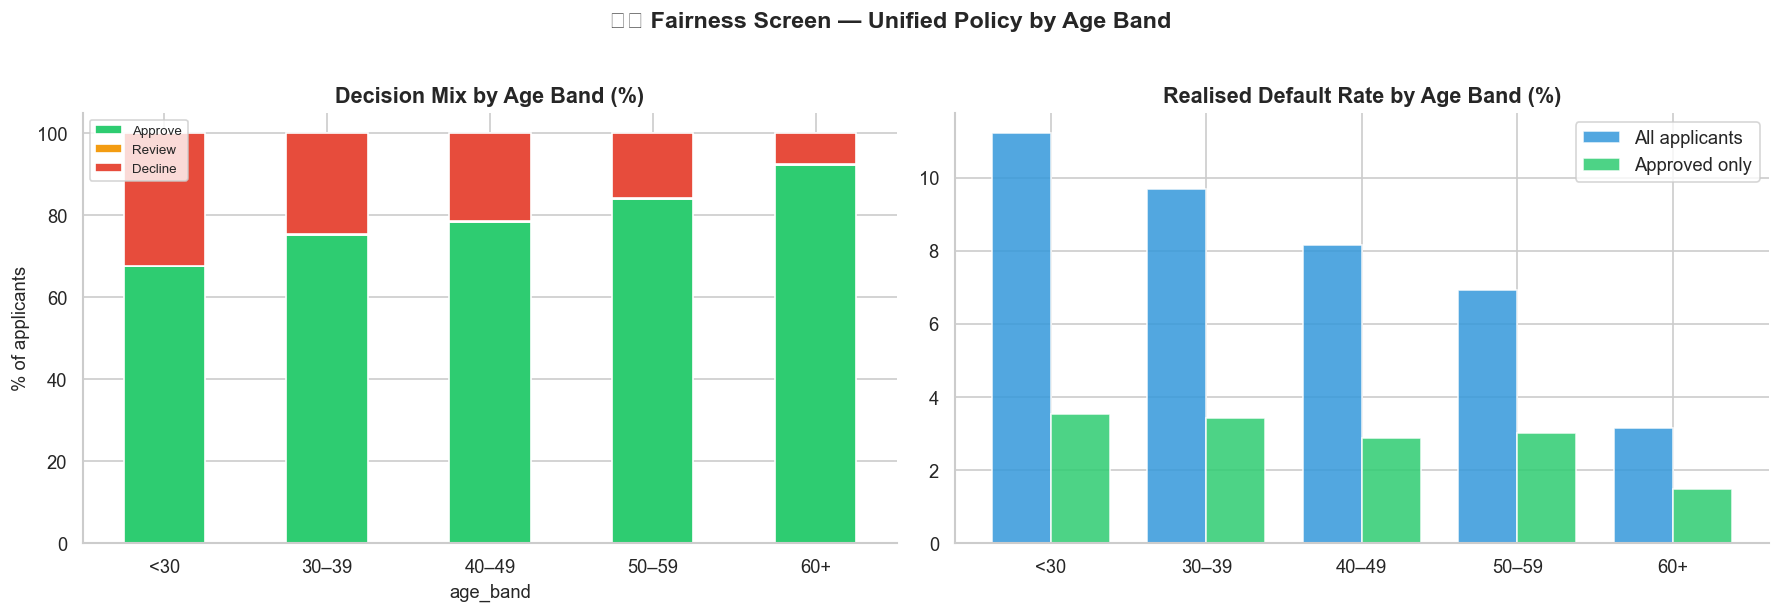

In [13]:
age_bins   = [0, 29, 39, 49, 59, 200]
age_labels = ["<30", "30–39", "40–49", "50–59", "60+"]
pe = port_eval.copy()
pe["decision"] = decisions_eval["Unified matrix"]
pe["age_band"] = pd.cut(pe["age"], age_bins, labels=age_labels)

seg = pe.groupby("age_band", observed=True).agg(
    applicants=("decision", "size"),
    approve_pct=("decision", lambda s: (s == 0).mean() * 100),
    review_pct=("decision", lambda s: (s == 1).mean() * 100),
    decline_pct=("decision", lambda s: (s == 2).mean() * 100),
    default_rate_pct=("y_def", lambda s: s.mean() * 100))
seg["approved_default_rate_pct"] = pe[pe.decision == 0].groupby("age_band", observed=True)["y_def"].mean() * 100
display(seg.round(2))

air = seg["approve_pct"].min() / seg["approve_pct"].max()
print(f"Adverse-impact ratio (min / max approval rate): {air:.2f}   (screening rule of thumb: ≥ 0.80)")

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
seg[["approve_pct", "review_pct", "decline_pct"]].plot.bar(stacked=True, color=[GOOD_COLOR, WARN_COLOR, BAD_COLOR], ax=ax[0], rot=0)
ax[0].set_title("Decision Mix by Age Band (%)"); ax[0].set_ylabel("% of applicants"); ax[0].legend(["Approve", "Review", "Decline"], fontsize=8)
x = np.arange(len(seg)); w = 0.38
ax[1].bar(x - w / 2, seg["default_rate_pct"], w, color=ACCENT_COLOR, alpha=0.85, label="All applicants")
ax[1].bar(x + w / 2, seg["approved_default_rate_pct"], w, color=GOOD_COLOR, alpha=0.85, label="Approved only")
ax[1].set_xticks(x); ax[1].set_xticklabels(seg.index); ax[1].set_title("Realised Default Rate by Age Band (%)"); ax[1].legend()
plt.suptitle("⚖️ Fairness Screen — Unified Policy by Age Band", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

📌 **Observation:**

| Age band | Applicants | Approve | Decline | Default rate (all) | Default rate (approved) |
|---|---|---|---|---|---|
| < 30 | 918 | 67.5% | 32.4% | 11.22% | 3.55% |
| 30–39 | 2,290 | 75.2% | 24.6% | 9.69% | 3.42% |
| 40–49 | 3,495 | 78.3% | 21.5% | 8.15% | 2.89% |
| 50–59 | 3,472 | 84.0% | 15.9% | 6.94% | 3.02% |
| 60+ | 4,765 | 92.4% | 7.4% | 3.15% | 1.48% |

- Approval rises steadily with age: the youngest band is **declined 4.4× as often as the oldest** (32.4% vs 7.4%), which mirrors a 3.6× spread in raw default rates (11.2% vs 3.2%). REVIEW is 0.1–0.2% in every band.
- The rule compresses risk rather than just following age: in the approved book the default-rate spread shrinks to **2.4×** (3.55% vs 1.48%), and the 30–59 bands are nearly equal (**2.9–3.4%**).
- **The adverse-impact ratio is 0.73** (67.5% ÷ 92.4%), below the 0.80 screening guideline. The <30 band is small (918 applicants), so the estimate is imprecise.

💡 **Pipeline decision:** The unified rule **does not pass the 0.80 screen**, so it cannot be released without a documented review. A **fairness gate** is added to the release checklist (approval-rate parity, error-rate parity and adverse-impact ratio per age band on every retrain). Compliance then decides whether the gap is justified risk differentiation or needs remediation; the pipeline is built so that age can be removed or constrained without redesign, and the profit cost of doing so is measured with `evaluate()`.

---
## Step 14 — Model Drivers and Reason-Code Preview
---
**Why:** **Permutation importance** measures how much a model's hold-out ROC-AUC drops when one feature is shuffled — a model-agnostic, leakage-safe ranking of what each score actually depends on. It confirms the EDA conclusions and gives the first draft of the **reason codes** attached to declines.  

**Business insight:** Regulators and customers are entitled to know the principal reasons for an adverse decision. The drivers of the credit score and of the fraud score are different, so the reason-code families are different too — and analysts reviewing a REVIEW case need to know which score triggered it.

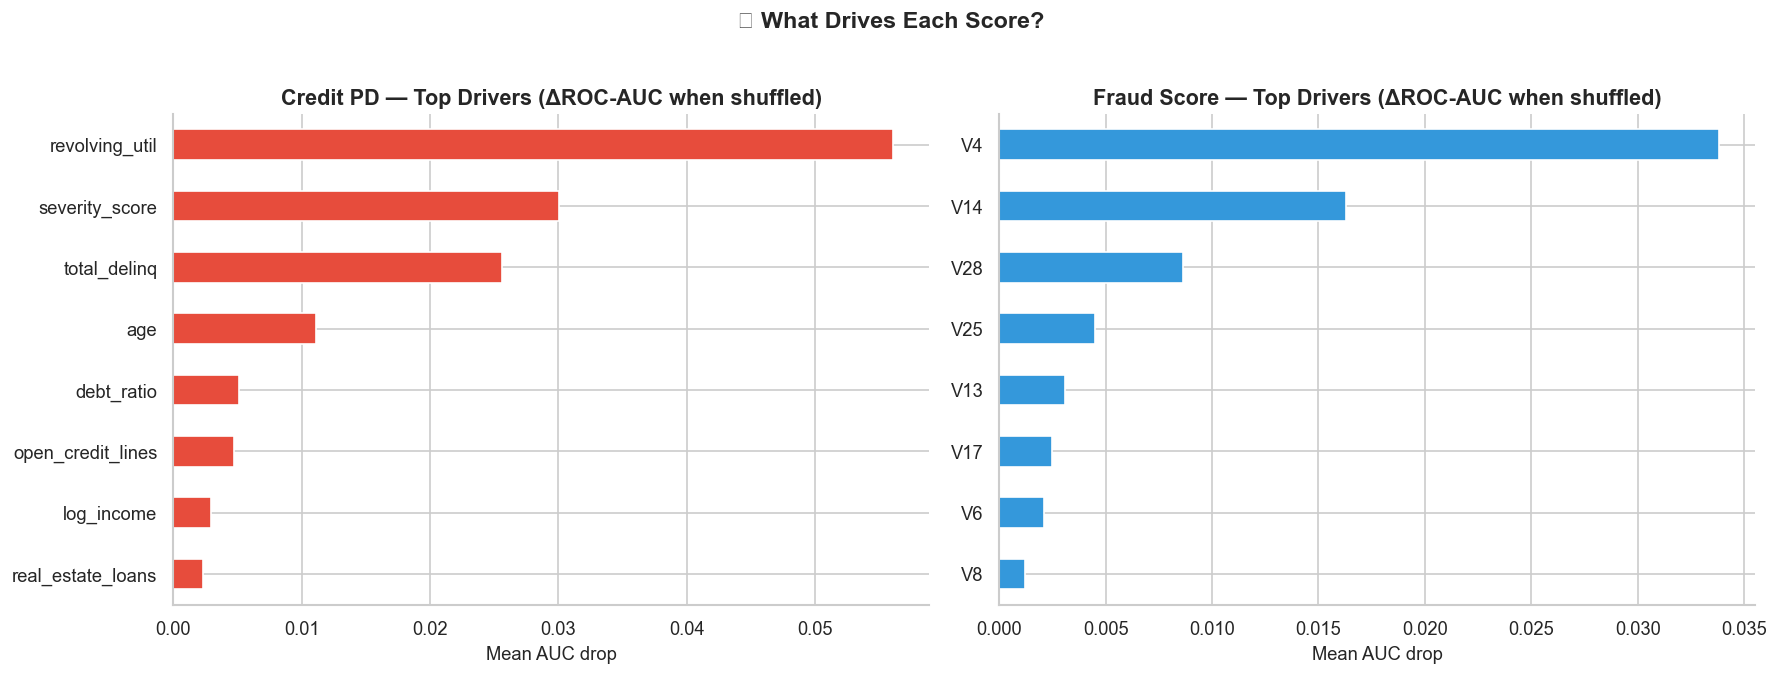

Draft credit reason codes (top 5 drivers):
  revolving_util         → High credit utilisation
  severity_score         → Severity of late payments
  total_delinq           → Recent late payments
  age                    → Limited credit history / age profile
  debt_ratio             → High debt burden


In [14]:
rng = np.random.default_rng(SEED)

# credit — random 15k sample of the hold-out
ci = rng.choice(len(Xc_hold), size=min(15000, len(Xc_hold)), replace=False)
pi_c = permutation_importance(credit_gbm, Xc_hold.iloc[ci], yc_hold.iloc[ci], scoring="roc_auc", n_repeats=3, random_state=SEED)
imp_c = pd.Series(pi_c.importances_mean, index=CREDIT_FEATURES).sort_values(ascending=False)

# fraud — all hold-out frauds + 20k legitimate rows
pos = np.where(yf_hold.values == 1)[0]
neg = rng.choice(np.where(yf_hold.values == 0)[0], size=min(20000, int((yf_hold == 0).sum())), replace=False)
fi = np.concatenate([pos, neg])
pi_f = permutation_importance(fraud_gbm, Xf_hold.iloc[fi], yf_hold.iloc[fi], scoring="roc_auc", n_repeats=3, random_state=SEED)
imp_f = pd.Series(pi_f.importances_mean, index=FRAUD_FEATURES).sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
imp_c.head(8)[::-1].plot.barh(color=BAD_COLOR, ax=ax[0]); ax[0].set_title("Credit PD — Top Drivers (ΔROC-AUC when shuffled)")
imp_f.head(8)[::-1].plot.barh(color=ACCENT_COLOR, ax=ax[1]); ax[1].set_title("Fraud Score — Top Drivers (ΔROC-AUC when shuffled)")
for a in ax: a.set_xlabel("Mean AUC drop")
plt.suptitle("🔍 What Drives Each Score?", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

REASON_FAMILY = {"revolving_util": "High credit utilisation", "total_delinq": "Recent late payments", "severity_score": "Severity of late payments",
                 "age": "Limited credit history / age profile", "debt_ratio": "High debt burden", "monthly_debt_payment": "High debt burden",
                 "log_income": "Income level", "open_credit_lines": "Number of credit lines", "over_limit_flag": "Over credit limit"}
print("Draft credit reason codes (top 5 drivers):")
for f in imp_c.head(5).index: print(f"  {f:<22} → {REASON_FAMILY.get(f, f)}")

📌 **Observation:**

- **Credit PD drivers (AUC drop when shuffled):** `revolving_util` **0.056**, `severity_score` **0.030**, `total_delinq` **0.026**, `age` 0.011, `debt_ratio` 0.005, `open_credit_lines` 0.005, `log_income` 0.003, `real_estate_loans` 0.002. Utilisation alone matters almost twice as much as the next feature, and the two delinquency aggregates are the next-largest block — consistent with the IV ranking in `02_credit_risk_eda`.
- **Fraud score drivers:** `V4` **0.034**, `V14` **0.016**, `V28` 0.009, `V25` 0.0045, `V13` 0.003, `V17` 0.0025, `V6` 0.002, `V8` 0.001. `V4` ranks first, ahead of `V14`; `V17` is only sixth.
- This ordering differs from the univariate EDA, where V14, V3, V17 and V12 led and V13 and V25 showed almost no separation. The model uses V28, V25 and V13 through interactions or chance — with 95 hold-out frauds, the lower-ranked fraud importances are not stable.
- The draft credit reason codes follow the top drivers: high utilisation, severity of late payments, recent late payments, age profile, debt burden.

💡 **Pipeline decision:**

- Credit declines return **business-language reason codes** mapped from the top drivers (maintained by credit policy, not by data science). Fraud declines return only the **reason family** (`FRAUD_HIGH` / `FRAUD_REVIEW`) — the PCA components are anonymised and a fraud model's detailed drivers are not disclosed to applicants.
- SHAP replaces permutation importance for per-applicant explanations in the API, and fraud-driver stability is checked with repeated CV before any driver is quoted.

---
## Step 15 — Key Insights Summary and Decision-Engine Export
---
**Why:** The last step consolidates results into one headline table and exports every parameter the production `decision_engine()` needs — band thresholds, matrix, economics, metrics and caps — to a single versioned JSON file, so the notebook and the deployed service cannot drift apart.  

**Business insight:** A versioned configuration file is the audit trail for the decision engine: which thresholds were live, which economic assumptions justified them and what performance they achieved when approved.

In [15]:
unified = pol.loc["Unified matrix"]
print("=" * 72)
print("  UNIFIED RISK ANALYSIS — COMPLETE")
print("=" * 72)
print(f"  Credit PD   (hold-out)  ROC-AUC {roc_auc_score(yc_hold, pd_hold):.3f} | KS {ks_stat(yc_hold, pd_hold):.3f} | Brier {brier_score_loss(yc_hold, pd_hold):.4f}")
print(f"  Fraud score (hold-out)  ROC-AUC {roc_auc_score(yf_hold, fs_hold):.3f} | PR-AUC {average_precision_score(yf_hold, fs_hold):.3f}")
print(f"  Chosen thresholds       pd_lo {PD_LO_RATIO*BEST_PD_HI:.3f} | pd_hi {BEST_PD_HI:.2f} | f_lo {F_LO_RATIO*BEST_F_HI:.3f} | f_hi {BEST_F_HI:.2f}")
print(f"  Unified policy (eval)   profit/applicant ${unified['profit_per_applicant']:,.0f} | review {unified['review_%']:.1f}% | final approval {unified['final_approval_%']:.1f}%")
print(f"  Credit-only (eval)      profit/applicant ${pol.loc['Credit-only', 'profit_per_applicant']:,.0f}")
print(f"  Fraud-only  (eval)      profit/applicant ${pol.loc['Fraud-only', 'profit_per_applicant']:,.0f}")
print("=" * 72)

engine_config = {
    "version": "0.1-simulation",
    "note": "Thresholds tuned on a SIMULATED application portfolio (credit and fraud datasets share no key). Re-tune on real joined data.",
    "bands": {"pd_lo": PD_LO_RATIO * BEST_PD_HI, "pd_hi": BEST_PD_HI, "fraud_lo": F_LO_RATIO * BEST_F_HI, "fraud_hi": BEST_F_HI},
    "decision_matrix": {"rows": "PD band low/medium/high", "cols": "fraud band low/medium/high",
                        "values": {"0": "APPROVE", "1": "REVIEW", "2": "DECLINE"}, "matrix": MATRIX.tolist()},
    "reason_codes": {f"{k[0]}-{k[1]}": v for k, v in REASONS.items()},
    "economics": {"loan_amount": LOAN_AMOUNT, "margin_rate": MARGIN_RATE, "lgd": LGD, "fraud_loss_rate": FRAUD_LOSS_RATE,
                  "review_cost": REVIEW_COST, "review_fraud_catch": REVIEW_FRAUD_CATCH, "review_credit_catch": REVIEW_CREDIT_CATCH,
                  "review_false_decline": REVIEW_FALSE_DECLINE, "assumed_application_fraud_rate": APP_FRAUD_RATE},
    "fraud_prior_shift": {"training_prevalence": FRAUD_PRIOR, "application_prevalence": APP_FRAUD_RATE},
    "credit_preprocessing": {"caps": CAPS, "age_median": AGE_MEDIAN, "feature_medians": CREDIT_MEDIANS.round(6).to_dict(),
                             "features": CREDIT_FEATURES, "monotonic_constraints": dict(zip(CREDIT_FEATURES, CREDIT_MONOTONIC))},
    "fraud_features": FRAUD_FEATURES,
    "calibration": {"credit": "isotonic (separate calibration split)", "fraud": "Platt / sigmoid (separate calibration split)"},
    "metrics_holdout": {"credit_roc_auc": roc_auc_score(yc_hold, pd_hold), "credit_ks": ks_stat(yc_hold, pd_hold),
                        "fraud_roc_auc": roc_auc_score(yf_hold, fs_hold), "fraud_pr_auc": average_precision_score(yf_hold, fs_hold)},
    "metrics_eval_portfolio": {k: float(v) for k, v in unified[["profit_per_applicant", "approve_%", "review_%", "decline_%", "final_approval_%"]].items()},
    "fairness_age_adverse_impact_ratio": float(air),
}
out = REPORT_DIR / "decision_engine_config.json"
out.write_text(json.dumps(engine_config, indent=2, default=float))
print(f"\nSaved → {out.resolve()}")

  UNIFIED RISK ANALYSIS — COMPLETE
  Credit PD   (hold-out)  ROC-AUC 0.865 | KS 0.585 | Brier 0.0490
  Fraud score (hold-out)  ROC-AUC 0.943 | PR-AUC 0.780
  Chosen thresholds       pd_lo 0.050 | pd_hi 0.10 | f_lo 0.020 | f_hi 0.05
  Unified policy (eval)   profit/applicant $511 | review 0.2% | final approval 83.1%
  Credit-only (eval)      profit/applicant $444
  Fraud-only  (eval)      profit/applicant $329

Saved → C:\Users\Narendra Kalam\Data_Science_Capstone_Projects\ai-loan-underwriting-platform\notebooks\reports\decision_engine_config.json


📌 **Observation:**

- Final results: credit PD **ROC-AUC 0.865 / KS 0.585 / Brier 0.0490**; fraud score **ROC-AUC 0.943 / PR-AUC 0.780**; chosen bands **pd_lo 0.05, pd_hi 0.10, f_lo 0.02, f_hi 0.05**.
- On the unseen evaluation portfolio the unified policy earns **$511 per applicant** with **0.2% review** and **83.1% final approval**, against **$444** for credit-only and **$329** for fraud-only.
- The advantage comes almost entirely from fraud losses that a credit model cannot remove ($1.19M → $0.16M); it shrinks to ≈ $2 per applicant at ρ = 0.8, scales linearly with the assumed fraud loss, and the rule's adverse-impact ratio by age band is **0.73** (< 0.80). All of it rests on a **simulated** portfolio and **illustrative** cost inputs.

💡 **Pipeline decision:** `reports/decision_engine_config.json` is loaded by `src/decision/decision_engine.py` and the FastAPI scoring service. Priorities after this notebook: (1) replace the simulation with real joined application data; (2) replace the illustrative economics (above all the three analyst-accuracy parameters) with finance-approved values and re-run Steps 9–13; (3) resolve the fairness gap and extend the fraud-threshold grid (Steps 10 and 13); (4) enlarge the fraud calibration data.

### 📋 EDA-to-Pipeline Decision Map

| # | Finding | Pipeline Decision |
|---|---------|-------------------|
| 1 | **Credit and fraud datasets share no applicant key** | Logic validated on a **simulated** portfolio (ρ ≈ 0.005); replace with real joined data before go-live |
| 2 | **Raw credit score mean 0.324 vs actual 0.067; fraud raw mean 0.00365 vs 0.00167** | Isotonic calibration (PD) and Platt scaling (fraud), each on a separate calibration split; Brier 0.147 → 0.049 |
| 3 | **Only 95 hold-out / 94 calibration frauds; ~18% of frauds score at the same floor as legitimate traffic** | Enlarge fraud data with a time-based hold-out; add device / identity signals; compare models by repeated CV |
| 4 | **Credit classes overlap broadly (PD 0.03–0.15); fraud score is bimodal (floor vs ≈ 0.9)** | Pricing / review band for credit; high-threshold decline for fraud |
| 5 | **Fraud applicants spread over the whole PD range (0 – 0.56)** | Credit-only approves fraud at a 0.95% rate → unified matrix with fraud-first DECLINE |
| 6 | **Fraud recall is flat at 0.821 for thresholds 0.005–0.05; 106 alerts at 0.05 (precision 0.74)** | Fraud operating region starts at ≈ 0.05; extend the Step 10 grid below it |
| 7 | **Approve-all $242; review-all $441 (generous analyst assumptions)** | Calibrate `REVIEW_*_CATCH` and false-decline parameters from real review outcomes |
| 8 | **Profit: PD threshold matters ($443 – $487), fraud threshold ≤ $2; REVIEW ≤ 0.2%** | pd_hi 0.10, f_hi 0.05; ⚠️ capacity-constrained REVIEW band instead of the fixed ratio |
| 9 | **Unified $511 vs credit-only $444 (+$67.7 ≈ +$1.01M); fraud loss $1.19M → $0.16M** | Unified matrix as champion, single-model rules as shadow challengers; bootstrap CI before quoting |
| 10 | **Advantage falls to ≈ $2 at ρ = 0.8; linear in fraud loss ($33 – $102); insensitive to LGD** | Report a range over ρ and fraud-loss values; monitor live ρ |
| 11 | **Adverse-impact ratio by age band 0.73 (< 0.80); <30 declined 4.4× as often as 60+** | Fairness gate in the release checklist; compliance review; age removable without redesign |
| 12 | **Drivers: utilisation (0.056), severity score, total delinquency; fraud V4, V14** | Business-language reason codes for credit; reason family only for fraud; SHAP in the API |

---

### 🏗️ Pipeline Flow (Applicant → Decision)

*(module names are the proposed `src/` layout for the capstone)*

```
Loan application
   │
   ├─▶ credit_features()          → cleaning rules from 02_credit_risk_eda (sentinels, DTI repair, caps)
   │     ▼  credit_gbm (monotonic) → isotonic calibration → PD
   │
   ├─▶ fraud_features()           → rules from 01_fraud_eda (log_amount, cyclic hour; no raw day, no graph score)
   │     ▼  fraud_gbm              → Platt calibration → prior-shift to application prevalence → fraud probability
   │
   ▼  decision_engine()           → band PD (low / medium / high) × band fraud (low / medium / high) → 3 × 3 matrix
   │                                 → APPROVE | REVIEW | DECLINE  + reason code
   ▼  policy overrides            → hard rules / VIP lists (outside the model layer)
   ▼  FastAPI /decision           → response: decision, PD, fraud score, reason code, config version
   ▼  Streamlit dashboard         → decision mix, review queue size, calibration drift, fairness gate, PSI
   ▼  Champion-Challenger         → unified matrix vs credit-only / fraud-only shadow policies, profit per applicant
```

---

*Analysis by Narendra Kalam — AI Loan Underwriting Platform (Unified Risk Module)*